In [1]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
import app.services.plotting_utils as plotutils

import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

### ML

In [5]:
apt_iata = "FLR"
folder = os.path.join("data", "hist_schedule")

files = [
    os.path.join(folder, f)
    for f in os.listdir(folder)
    if f.endswith(".csv")
]

df = pd.concat(
    [pd.read_csv(file, sep=';', low_memory=False) for file in files],
    ignore_index=True
)

#filter schedule
df_f = df[(df['AVIAZIONE'] == 'Commerciale') & (df['NATURA'] == 'P') & (df['SCALO_TECNICO'] == 0) & (df['ADULT'] != 0) & (~df['NUMERO_MASSIMO_PAX'].isna()) & 
          ((df['ADULT']+df['CHILD']) <= df['NUMERO_MASSIMO_PAX'])]

df_f

,ID_VOLO,ID_LEGATO,DATA_VOLO,NOME_ESERCENTE,NAME_CARRIER,MATRICOLA_AEROMOBILE,PESO_MASSIMO,MODELLO_AEROMOBILE,NUMERO_MASSIMO_PAX,CODICE_ICAO,...,CERTIFICATO,ESPORTATO,GATE,VOLO_RISCHEDULATO,STATO_ATTIVITA,READY,CERT_TIMESTAMP,DATA_DIR_CANC,CAUSALE_DIR_CANC,MERCE_ESENTE
29,26808735,26808210.0,20170101,NaN,AIR FRANCE,FGUGI,60.0,A318,131.0,AFR,...,S,S,NaN,NaN,Completato,NaN,2017-01-02 08:56:31.000,NaN,NaN,NaN
30,26808742,26808231.0,20170101,NaN,KLM-ROYAL DUTCH AIRLINES,PHEZO,45.0,E190,100.0,KLM,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 07:11:01.000,NaN,NaN,NaN
31,26808756,26808217.0,20170101,NaN,LUFTHANSA,DAECD,51.0,E190,94.0,DLH,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 08:24:24.000,NaN,NaN,NaN
32,26808763,26808196.0,20170101,NaN,VUELING AIRLINES,ECMKV,64.0,A319,144.0,VLG,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 09:31:49.000,NaN,NaN,NaN
33,26808770,26808189.0,20170101,NaN,SWISS,HBJVP,51.0,E190,110.0,SWR,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 10:52:52.000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,68716698,68716533.0,20251218,NaN,ITA AIRWAYS,EIIMB,64.0,A319,144.0,ITY,...,S,S,GATE 1,NaN,Completato,NaN,2026-01-05 10:55:26.000,NaN,NaN,0.0
314427,68924169,68923996.0,20251208,NaN,AIR SERBIA,YUAPF,68.0,A319,144.0,ASL,...,S,S,GATE 11,NaN,Completato,NaN,2025-12-08 21:27:43.000,NaN,NaN,0.0
314477,69100636,64538481.0,20251205,NaN,VOLOTEA,ECNGL,66.0,A319,156.0,VOE,...,S,S,GATE 2,NaN,Completato,NaN,2025-12-09 08:57:58.000,NaN,NaN,0.0
314736,69688892,64545032.0,20251217,NaN,AIR FRANCE,FHZUX,64.0,BCS3,148.0,AFR,...,S,S,GATE 3,NaN,Completato,NaN,2025-12-17 12:40:04.000,NaN,NaN,0.0


In [6]:
def standardize_df(df):
    df=df.copy()

    col_mapping= {'DATA_PREVISTA': 'date', 'ORA_PREVISTA': 'schtime', 
                  'CODICE_IATA':'car', 'CODICE_ICAO': 'car_icao', 'NUMERO_VOLO': 'flt_n', 'DESTINAZIONE': 'apt', 
                  'MODELLO_AEROMOBILE': 'ac', 'NUMERO_MASSIMO_PAX':'seats', 'ADULT': 'adults', 'CHILD': 'children', 'NUM_BAGAGLI': 'luggage'}
    df = df[col_mapping.keys()].copy()
    df.rename(columns=col_mapping, inplace=True)

    df["date"] = pd.to_datetime(df["date"].astype("string"), format="%Y%m%d", errors="coerce")

    df['week_day']= df['date'].dt.day_name(locale='en_US')
    df['month'] = df['date'].dt.month_name(locale='en_US')
    df['year'] = df['date'].dt.year

    schtime = (
        df["schtime"]
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.zfill(4)
    )

    schtime_dt = pd.to_datetime(
        schtime,
        format="%H%M",
        errors="coerce"
    )

    df["schtime"] = schtime_dt.dt.strftime("%H:%M")

    hour_decimal = schtime_dt.dt.hour + schtime_dt.dt.minute / 60

    df["sin_hour"] = np.sin(2 * np.pi * hour_decimal / 24)
    df["cos_hour"] = np.cos(2 * np.pi * hour_decimal / 24)

    df["fdatetime"] = pd.to_datetime(
        df["date"].dt.strftime("%Y-%m-%d")
        + " "
        + df["schtime"],
        errors="coerce"
    )

    # Carrier code
    df["car"] = (
        df["car"]
        .fillna(df["car_icao"])
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df = df[df["car"] != "_"].copy()

    # Flight number
    df["flt_n"] = (
        df["flt_n"]
        .fillna("")
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.replace(" ", "", regex=False)
        .str.upper()
        .str.replace(r"^0+(?=.)", "", regex=True)
    )

    # nflt = carrier + flight number, con uno spazio
    df["nflt"] = df["car"] + " " + df["flt_n"]
    df.drop(columns=["car_icao", 'flt_n'], inplace=True)

    df["ac"] = (
        df["ac"]
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df['pax'] = df['adults'] + df['children']
    df["load_factor"] = df["pax"] / df["seats"]

    return df

df1 = standardize_df(df_f)
# remove covid years
df1 = df1[~df1['year'].isin([2020, 2021])].copy()
print(df1.shape)
df1

(102722, 18)


,date,schtime,car,apt,ac,seats,adults,children,luggage,week_day,month,year,sin_hour,cos_hour,fdatetime,nflt,pax,load_factor
29,2017-01-01,06:20,AF,CDG,A318,131.0,115,10,101,Sunday,January,2017,0.996195,-0.087156,2017-01-01 06:20:00,AF 1267,125,0.954198
30,2017-01-01,06:30,KL,AMS,E190,100.0,95,2,117,Sunday,January,2017,0.991445,-0.130526,2017-01-01 06:30:00,KL 1638,97,0.970000
31,2017-01-01,07:20,LH,FRA,E190,94.0,89,2,79,Sunday,January,2017,0.939693,-0.342020,2017-01-01 07:20:00,LH 319,91,0.968085
32,2017-01-01,08:50,VY,MAD,A319,144.0,89,5,36,Sunday,January,2017,0.737277,-0.675590,2017-01-01 08:50:00,VY 1506,94,0.652778
33,2017-01-01,09:50,LX,ZRH,E190,110.0,81,11,80,Sunday,January,2017,0.537300,-0.843391,2017-01-01 09:50:00,LX 1679,92,0.836364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,2025-12-18,11:10,AZ,FCO,A319,144.0,118,1,142,Thursday,December,2025,0.216440,-0.976296,2025-12-18 11:10:00,AZ 1678,119,0.826389
314427,2025-12-08,20:20,JU,BEG,A319,144.0,67,1,45,Monday,December,2025,-0.819152,0.573576,2025-12-08 20:20:00,JU 469,68,0.472222
314477,2025-12-05,18:40,V7,CTA,A319,156.0,124,7,11,Friday,December,2025,-0.984808,0.173648,2025-12-05 18:40:00,V7 1705,131,0.839744
314736,2025-12-17,12:20,AF,CDG,BCS3,148.0,122,4,82,Wednesday,December,2025,-0.087156,-0.996195,2025-12-17 12:20:00,AF 1367,126,0.851351


##### creazione base per futuri voli

In [57]:
def build_ac_lookup(
    df: pd.DataFrame,
    lookback_days: int = 730,
    min_flights: int = 10,
):
    """
    Costruisce i lookup usando solo gli ultimi `lookback_days` giorni di storico
    (default 2 anni), per riflettere flotta/rotte attuali, non quelle del 2017.
 
    Catena di fallback:
      seats:  nflt -> (car, ac) -> ac -> global
      ac:     nflt -> (car, apt) -> car -> global
 
    Il livello "nflt" (numero di volo specifico) e' il piu' preciso: uno stesso
    numero di volo tende a essere operato in modo consistente dallo stesso
    equipaggiamento/capacita' nel tempo.
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
 
    cutoff = df["date"].max() - pd.Timedelta(days=lookback_days)
    recent = df[df["date"] >= cutoff]
 
    valid = recent[["car", "apt", "ac", "seats", "nflt"]].dropna()
    valid = valid[valid["seats"] > 0]
 
    # --- capienza tipica per nflt (primo livello, il piu' specifico) ---
    nflt_seats_stats = (
        valid.groupby("nflt")["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_nflt = (
        nflt_seats_stats[nflt_seats_stats["n_flights"] >= min_flights]
        .set_index("nflt")["seats"]
        .astype(int)
    )
 
    # --- capienza tipica per car, ac (fallback) ---
    car_ac_stats = (
        valid.groupby(["car", "ac"])["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_car_ac = (
        car_ac_stats[car_ac_stats["n_flights"] >= min_flights]
        .set_index(["car", "ac"])["seats"]
        .astype(int)
    )
 
    # --- capacita' tipica per solo ac (fallback finale prima del globale) ---
    seats_by_ac = (
        valid.groupby("ac")["seats"]
        .agg(lambda s: s.mode().iloc[0])
        .astype(int)
    )
 
    # --- modello aereo piu' usato per nflt (primo livello, il piu' specifico) ---
    nflt_ac_counts = (
        valid.groupby(["nflt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    nflt_totals = nflt_ac_counts.groupby("nflt")["n_flights"].transform("sum")
 
    ac_by_nflt = (
        nflt_ac_counts[nflt_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["nflt"], keep="first")
        .set_index("nflt")["ac"]
    )
 
    # --- modello piu' usato per car, apt (fallback) ---
    route_counts = (
        valid.groupby(["car", "apt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    route_totals = route_counts.groupby(["car", "apt"])["n_flights"].transform("sum")
 
    route_ac = (
        route_counts[route_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car", "apt"], keep="first")
        .set_index(["car", "apt"])["ac"]
    )
 
    # --- modello piu' usato per carrier (fallback finale prima del globale) ---
    carrier_counts = (
        valid.groupby(["car", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    carrier_totals = carrier_counts.groupby("car")["n_flights"].transform("sum")
 
    carrier_ac = (
        carrier_counts[carrier_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car"], keep="first")
        .set_index("car")["ac"]
    )
 
    # --- fallback globale ---
    global_ac = valid["ac"].mode().iloc[0]
    global_seats = valid["seats"].mode().iloc[0]
 
    return {
        "seats_by_nflt": seats_by_nflt,
        "seats_by_car_ac": seats_by_car_ac,
        "seats_by_ac": seats_by_ac,
        "ac_by_nflt": ac_by_nflt,
        "route_ac": route_ac,
        "carrier_ac": carrier_ac,
        "global_ac": global_ac,
        "global_seats": global_seats,
    }

In [58]:
ac_lookup_bundle = build_ac_lookup(df1)

save_path = os.path.join("data", apt_iata, "ac_lookup.joblib")
os.makedirs(os.path.dirname(save_path), exist_ok=True)
joblib.dump(ac_lookup_bundle, save_path)

['data\\FLR\\ac_lookup.joblib']

##### testing

                 pax          seats    load_factor
count  102722.000000  102722.000000  102722.000000
mean      101.434279     127.629349       0.792031
std        27.822603      23.002886       0.162514
min         1.000000       6.000000       0.006944
5%         52.000000      94.000000       0.455133
25%        85.000000     112.000000       0.713115
50%       102.000000     131.000000       0.833333
75%       123.000000     144.000000       0.910000
95%       142.000000     156.000000       0.979167
99%       150.000000     180.000000       1.000000
max       174.000000     189.000000       1.000000


Text(0.5, 1.0, 'Distribution of pax per flight')

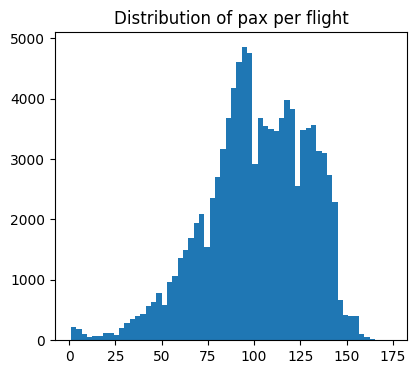

In [7]:
# outliers in pax e luaggage
print(df1[["pax", "seats", "load_factor"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

plt.figure(figsize=(10,4))
plt.subplot(121)
hist = plt.hist(df1["pax"], bins=60)
plt.title("Distribution of pax per flight")

In [8]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

def regression_report(y_true, y_pred, title=""):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    mask = y_true != 0
    mape = (
        np.mean(
            np.abs(
                (y_true[mask] - y_pred[mask]) / y_true[mask]
            )
        ) * 100
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
        * 100
    )

    print(title)
    print(f"MAE: {mae:.2f}")
    print(f"MAPE: {mape:.2f} %")
    print(f"RMSE: {rmse:.2f}")
    print(f"WAPE: {wape:.2f} %")
    print(f"R2: {r2:.3f}")

In [9]:
def baseline_model(train, val):

    train = train.copy()
    val = val.copy()

    global_lf = train["pax"].mean()

    mean_full = (
        train
        .groupby(["car", "apt", "ac", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt_month = (
        train
        .groupby(["car", "apt", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt = (
        train
        .groupby(["car", "apt"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car = (
        train
        .groupby("car")["pax"]
        .mean()
        .rename("pred_pax")
    )

    out = val.copy()

    # livello più specifico
    out = out.merge(
        mean_full,
        on=["car", "apt", "ac", "month"],
        how="left"
    )

    # fallback car + apt + month
    fallback = out.merge(
        mean_car_apt_month,
        on=["car", "apt", "month"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback car + apt
    fallback = out.merge(
        mean_car_apt,
        on=["car", "apt"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback carrier
    fallback = out.merge(
        mean_car,
        on="car",
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # ultimo fallback: media globale
    out["pred_pax"] = out["pred_pax"].fillna(global_lf)

    return out

In [10]:
# validation 2024 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Validation 2024")

#Baseline Validation 2024
MAE: 13.64
MAPE: 15.62 %
RMSE: 17.88
WAPE: 12.50 %
R2: 0.508


In [11]:
# test 2025 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Test 2025")

#Baseline Test 2025
MAE: 14.31
MAPE: 74.57 %
RMSE: 20.84
WAPE: 13.33 %
R2: 0.443


In [12]:
# validation 2024 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Validation PAX 2024")

# XGBoost Validation PAX 2024
MAE: 12.56
MAPE: 13.71 %
RMSE: 16.36
WAPE: 11.51 %
R2: 0.588


In [13]:
# test 2025 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Test PAX 2025")

# XGBoost Test PAX 2025
MAE: 11.74
MAPE: 17.36 %
RMSE: 15.76
WAPE: 10.93 %
R2: 0.682


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

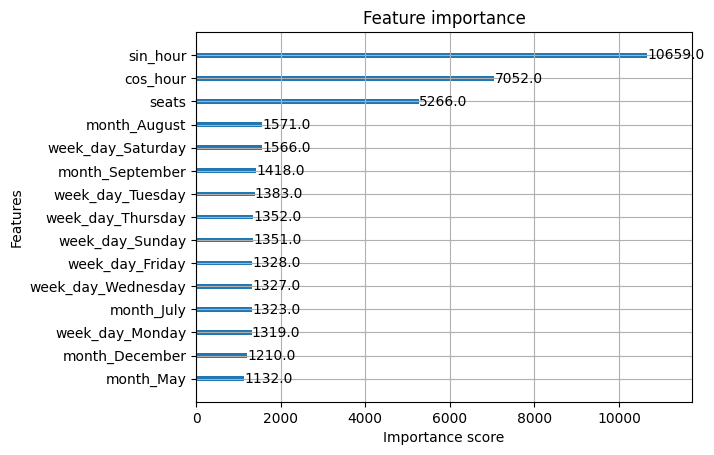

In [14]:
from xgboost import plot_importance
plot_importance(xgb_pax, max_num_features=15)

##### training for production

In [16]:
# training fino al 2025 incluso

df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2026
train = df.loc[train_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
y_train = train[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

# save model and encoders

import joblib

model_bundle = {
    "model": xgb_pax,
    "apt_encoder": apt_encoder,
    "other_encoder": other_encoder,
    "features": features,
    "apt_column": apt_column,
    "other_categorical_columns": other_categorical_columns,
    "numeric_columns": numeric_columns,
    "target": "pax",
}

joblib.dump(
    model_bundle,
    f"data/pax_model.joblib",
)

['data/pax_model.joblib']

### arrival curves

In [37]:
# entire schedule
apt_iata= 'FLR'

url = f"https://aosnice-api.toscana-aeroporti.com/{apt_iata}/getPlannedFlights"
response = requests.get(url)
response.raise_for_status()
data = response.json()
flights = data["RESPONSE"]["result"]["elements"]

rows = []
for f in flights:
    rows.append({
        "flight_number": f.get("number"),
        "nature": f.get("nature", {}).get("code"),
        "carrier": f.get("carrier", {}).get("publicCode"),
        "airport": f.get("airport", {}).get("code"),
        "periods": f.get("periods", [])
    })

all_flights = pd.DataFrame(rows)

# filter departures and explode periods
sched = all_flights[all_flights["nature"] == "P"].drop(columns=["nature"]).rename(columns={"airport": "apt"}).copy()
sched["periods"] = sched["periods"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
sched = (
    sched
    .explode("periods", ignore_index=True)
    .join(pd.json_normalize(sched.explode("periods")["periods"]))
    .drop(columns=["periods"])
)

sched["from"] = pd.to_datetime(sched["from"]).dt.normalize()
sched["to"] = pd.to_datetime(sched["to"]).dt.normalize()
sched["flight_number"] = (sched["flight_number"].astype(str).str.replace(r"\.0$", "", regex=True).str.lstrip("0"))
sched["freq"] = sched["frequency"].str.split(",")
sched.to_csv(os.path.join('data', 'schedule_all.csv'), index=False)

In [40]:
# security data
df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')
df_security = df_security[
    (df_security['LAST_POSITION'] == 'SECURITY_AREA') &
    (df_security['PASSAGE_AUTHORIZED'] == 1)
].copy()

df_security["FLIGHT_NUMBER"] = df_security["FLIGHT_NUMBER"].astype(str).str.lstrip("0")
df_security["DATE_OF_FLIGHT"] = pd.to_datetime(df_security["DATE_OF_FLIGHT"]).dt.normalize()
df_security["SCR_TIME"] = pd.to_datetime(df_security["SCR_TIME"], errors="coerce")

df_security = (
    df_security
    .sort_values('SCR_TIME')
    .drop_duplicates(subset='ID', keep='last')
    .reset_index(drop=True)
)

cols_to_keep = ['ID', 'DATE_OF_FLIGHT', 'OPERATING_CARRIER', 'FLIGHT_NUMBER', 'SCR_TIME']
df_security = df_security[cols_to_keep].copy()
df_security["weekday"] = df_security["DATE_OF_FLIGHT"].dt.isocalendar().day

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\4287610874.py:2: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')


In [42]:
# merge
sched = pd.read_csv(os.path.join('data', 'schedule_all.csv'))
sched['flight_number'] = sched['flight_number'].astype(str)

out = df_security.merge(
    sched,
    left_on=["OPERATING_CARRIER", "FLIGHT_NUMBER"],
    right_on=["carrier", "flight_number"],
    how="left"
).drop(columns=["carrier", "flight_number"])
out["frequency"] = out["frequency"].fillna("")

mask = (
    out["DATE_OF_FLIGHT"].between(out["from"], out["to"])
    &
    out.apply(
        lambda r: str(r["weekday"]) in r["frequency"].split(","),
        axis=1
    )
)

out = out[mask].copy()

out["SCR_TIME"] = pd.to_datetime(out["SCR_TIME"], errors="coerce")
out["time"] = pd.to_datetime(out["time"], errors="coerce")
out['flight_number'] = out['OPERATING_CARRIER'] + ' ' + out['FLIGHT_NUMBER']

out["departure_dt"] = (
    out["DATE_OF_FLIGHT"]
    + pd.to_timedelta(out["time"].dt.hour, unit="h")
    + pd.to_timedelta(out["time"].dt.minute, unit="m")
    + pd.to_timedelta(out["time"].dt.second, unit="s")
)

out["advance"] = (out["departure_dt"] - out["SCR_TIME"]).dt.total_seconds() / 60

out["month"] = out["departure_dt"].dt.month_name(locale="en_US")
out["departure_hour"] = out["departure_dt"].dt.hour
out["time_band"] = pd.cut(
    out["departure_hour"],
    bins=[-1, 5, 9, 13, 17, 21, 23],
    labels=[
        "00-05",
        "06-09",
        "10-13",
        "14-17",
        "18-21",
        "22-23",
    ]
)
out.rename(columns={"OPERATING_CARRIER": "car"}, inplace=True)

out["advance"].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    304311.000000
mean        105.636527
std          35.450038
min        -561.066667
1%           30.936667
5%           52.700000
10%          62.983333
25%          81.200000
50%         103.550000
75%         129.083333
90%         154.983333
95%         168.650000
99%         178.700000
max         347.183333
Name: advance, dtype: float64

In [43]:
# clean outliers
p5 = out["advance"].quantile(0.05)
p99 = out["advance"].quantile(0.999)

df_arrivals_clean = out[(out["advance"] <= p99) & (out["advance"] >= p5)].copy()

print(f"soglia p5: {p5:.1f} min")
print(f"soglia p99: {p99:.1f} min")
print("righe totali:", len(out))
print("righe rimosse:", len(out) - len(df_arrivals_clean))
print("righe rimanenti:", len(df_arrivals_clean))

soglia p5: 52.7 min
soglia p99: 201.5 min
righe totali: 304311
righe rimosse: 15512
righe rimanenti: 288799


#### test vari

In [44]:
def advance_summary(df, group_cols, min_count=100):

    summary = (
        df.groupby(group_cols)["advance"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            p05=lambda x: x.quantile(0.05),
            p25=lambda x: x.quantile(0.25),
            p75=lambda x: x.quantile(0.75),
            p95=lambda x: x.quantile(0.95),
        )
        .reset_index()
    )

    summary = summary[
        summary["count"] >= min_count
    ].copy()

    return summary.sort_values(
        "median",
        ascending=False
    )

def plot_boxplot(df, group_col, min_count=100, top_n=20):
    counts = df[group_col].value_counts()

    if isinstance(df[group_col].dtype, pd.CategoricalDtype):
        valid_groups = [
            g for g in df[group_col].cat.categories
            if counts.get(g, 0) >= min_count
        ]
    else:
        valid_groups = counts[counts >= min_count].index.tolist()

    valid_groups = valid_groups[:top_n]

    data = [
        df.loc[df[group_col] == g, "advance"].dropna()
        for g in valid_groups
    ]

    plt.figure(figsize=(12, 6))

    plt.boxplot(
        data,
        tick_labels=valid_groups,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 1,
            "alpha": 0.5,
            "markeredgewidth": 1,
        }
    )

    plt.ylabel("Minutes before departure")
    plt.xlabel(group_col)
    plt.title(f"Security advance by {group_col}")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

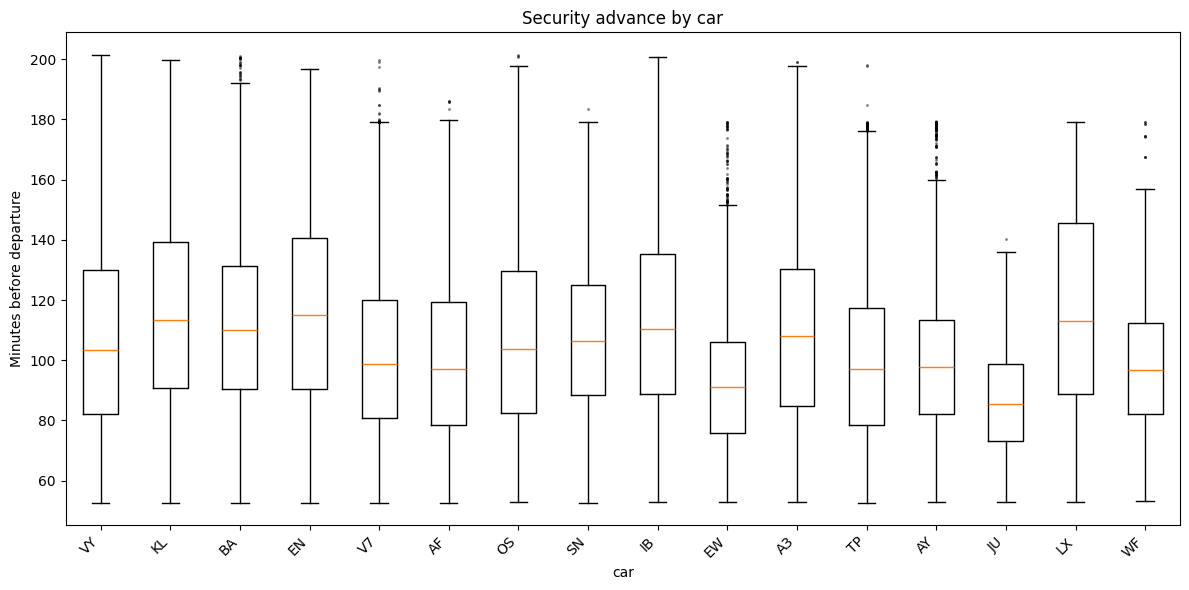

In [45]:
by_carrier = plot_boxplot(
    df_arrivals_clean,
    "car"
)

by_carrier

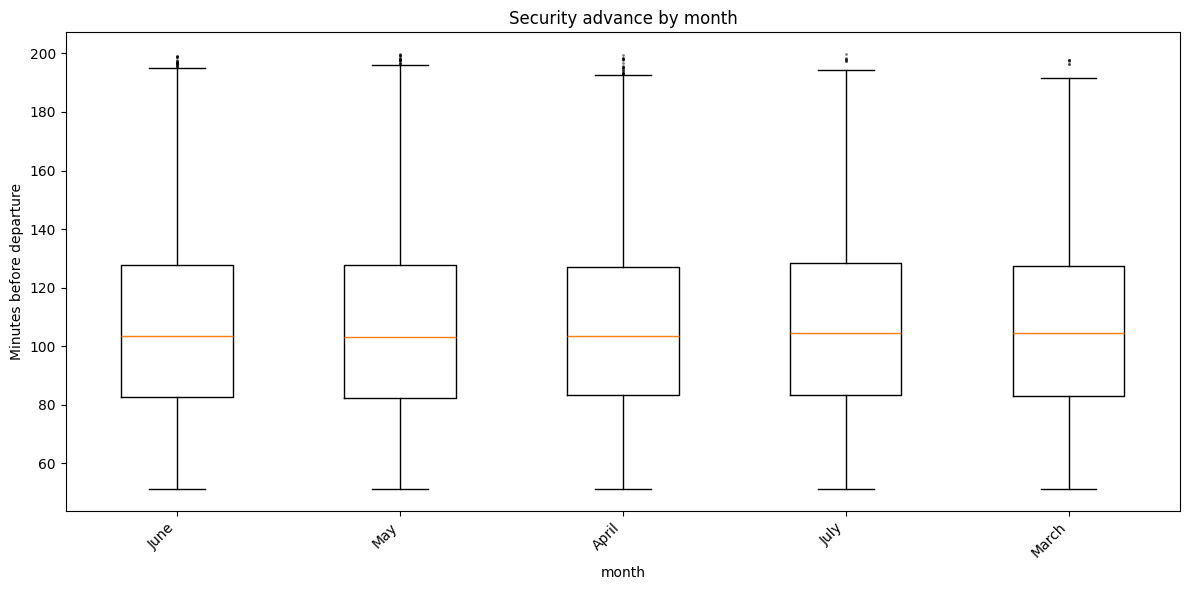

In [85]:
by_month = plot_boxplot(
    df_arrivals_clean,
    "month"
)

by_month

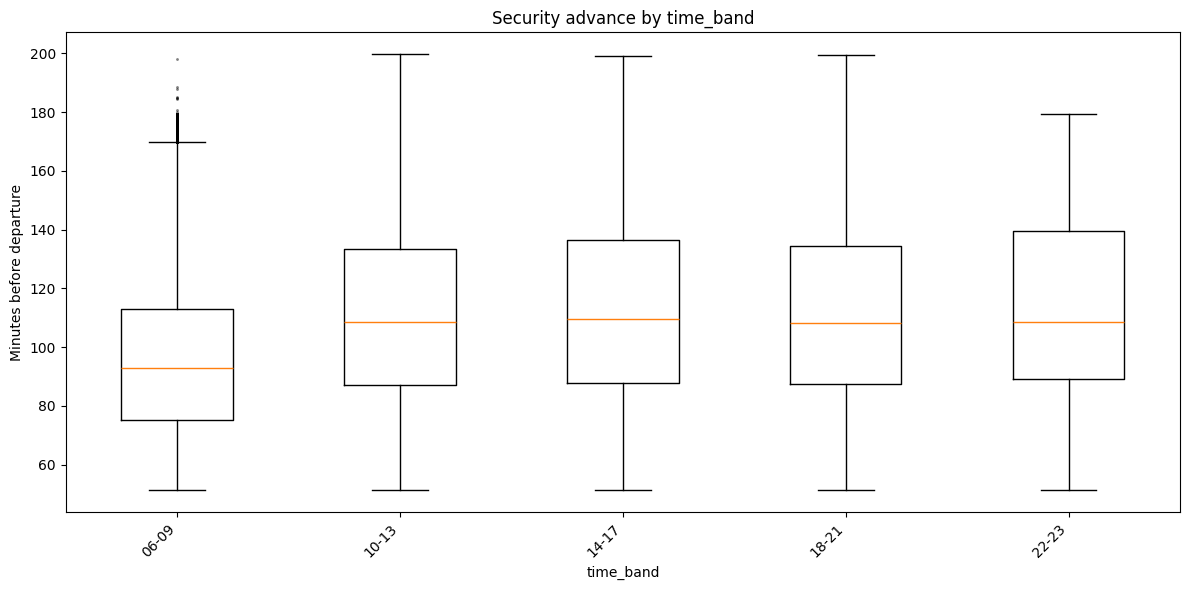

In [86]:
by_time = plot_boxplot(
    df_arrivals_clean,
    "time_band",
    min_count=1
)
by_time

#### normalizing flows

In [46]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import zuko

torch.manual_seed(42)
np.random.seed(42)

df_nf = df_arrivals_clean.copy()
df_nf["log_advance"] = np.log(df_nf["advance"])

cat_cols = ["car", "month", "time_band", "apt"]
MIN_FREQ = 10

code_lookup = {}
cardinalities = {}

for col in cat_cols:
    counts = df_nf[col].value_counts()
    keep = set(counts[counts >= MIN_FREQ].index)
    categories = sorted(keep) + ["UNK"]
    lookup = {cat: i for i, cat in enumerate(categories)}

    df_nf[col + "_code"] = df_nf[col].where(df_nf[col].isin(keep), "UNK").map(lookup)
    code_lookup[col] = lookup
    cardinalities[col] = len(categories)

print("cardinalità (incluso UNK):", cardinalities)

# split per volo
df_nf["flight_key"] = df_nf["flight_number"] + "_" + df_nf["DATE_OF_FLIGHT"].astype(str)

unique_flights = df_nf["flight_key"].unique()
rng = np.random.default_rng(42)
rng.shuffle(unique_flights)

n_val = int(0.15 * len(unique_flights))
val_flights = set(unique_flights[:n_val])
df_nf["is_val"] = df_nf["flight_key"].isin(val_flights)

train_df = df_nf[~df_nf["is_val"]].reset_index(drop=True)
val_df = df_nf[df_nf["is_val"]].reset_index(drop=True)

# standardizzazione log_advance (mean=0, std=1)
log_adv_mean = train_df["log_advance"].mean()
log_adv_std = train_df["log_advance"].std()

train_df["log_advance_std"] = (train_df["log_advance"] - log_adv_mean) / log_adv_std
val_df["log_advance_std"] = (val_df["log_advance"] - log_adv_mean) / log_adv_std

code_cols = [c + "_code" for c in cat_cols]

class AdvanceDataset(Dataset):
    def __init__(self, frame):
        self.y = torch.tensor(frame["log_advance_std"].to_numpy(), dtype=torch.float32).unsqueeze(-1)
        self.cats = torch.tensor(frame[code_cols].to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.y[idx], self.cats[idx]

train_loader = DataLoader(AdvanceDataset(train_df), batch_size=1024, shuffle=True)
val_loader = DataLoader(AdvanceDataset(val_df), batch_size=4096, shuffle=False)

cardinalità (incluso UNK): {'car': 17, 'month': 6, 'time_band': 6, 'apt': 26}


In [47]:
class Embedder(nn.Module):
    def __init__(self, cardinalities, embed_dim=8):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, embed_dim) for card in cardinalities.values()
        ])

    def forward(self, cats):
        parts = [emb(cats[:, i]) for i, emb in enumerate(self.embeddings)]
        return torch.cat(parts, dim=-1)

embed_dim = 8
embedder = Embedder(cardinalities, embed_dim=embed_dim)
context_dim = embed_dim * len(cat_cols)

flow = zuko.flows.NSF(
    features=1,
    context=context_dim,
    transforms=3,
    hidden_features=(64, 64),
)

optimizer = torch.optim.Adam(
    list(embedder.parameters()) + list(flow.parameters()),
    lr=1e-3,
)

def run_epoch(loader, train=True):
    embedder.train(train)
    flow.train(train)
    total_loss, n = 0.0, 0

    for y, cats in loader:
        context = embedder(cats)
        dist = flow(context)
        loss = -dist.log_prob(y).mean()

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * len(y)
        n += len(y)

    return total_loss / n

best_val = float("inf")
patience, bad_epochs = 8, 0
best_state = None

for epoch in range(200):
    train_nll = run_epoch(train_loader, train=True)
    with torch.no_grad():
        val_nll = run_epoch(val_loader, train=False)

    print(f"epoch {epoch+1:03d}  train NLL {train_nll:.4f}  val NLL {val_nll:.4f}")

    if val_nll < best_val:
        best_val = val_nll
        bad_epochs = 0
        best_state = (
            {k: v.clone() for k, v in embedder.state_dict().items()},
            {k: v.clone() for k, v in flow.state_dict().items()},
        )
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"early stopping all'epoca {epoch+1} (miglior val NLL: {best_val:.4f})")
            break

embedder.load_state_dict(best_state[0])
flow.load_state_dict(best_state[1])

epoch 001  train NLL 1.3169  val NLL 1.2962
epoch 002  train NLL 1.2959  val NLL 1.2985
epoch 003  train NLL 1.2918  val NLL 1.2931
epoch 004  train NLL 1.2881  val NLL 1.2901
epoch 005  train NLL 1.2854  val NLL 1.2937
epoch 006  train NLL 1.2852  val NLL 1.2874
epoch 007  train NLL 1.2834  val NLL 1.2939
epoch 008  train NLL 1.2824  val NLL 1.2904
epoch 009  train NLL 1.2810  val NLL 1.2890
epoch 010  train NLL 1.2803  val NLL 1.2904
epoch 011  train NLL 1.2813  val NLL 1.2889
epoch 012  train NLL 1.2779  val NLL 1.2910
epoch 013  train NLL 1.2786  val NLL 1.2879
epoch 014  train NLL 1.2775  val NLL 1.2900
early stopping all'epoca 14 (miglior val NLL: 1.2874)


<All keys matched successfully>

In [48]:
def encode_value(col, value):
    lookup = code_lookup[col]
    return lookup.get(value, lookup["UNK"])

def sample_advance(car, month, time_band, apt, n_samples=5000):
    codes = [encode_value(c, v) for c, v in zip(cat_cols, [car, month, time_band, apt])]
    cats_tensor = torch.tensor([codes] * n_samples, dtype=torch.long)

    embedder.eval()
    flow.eval()
    with torch.no_grad():
        context = embedder(cats_tensor)
        z_samples = flow(context).sample()

    log_adv_samples = z_samples.squeeze(-1) * log_adv_std + log_adv_mean
    return torch.exp(log_adv_samples).numpy()

#### Validation

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\3716960570.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()


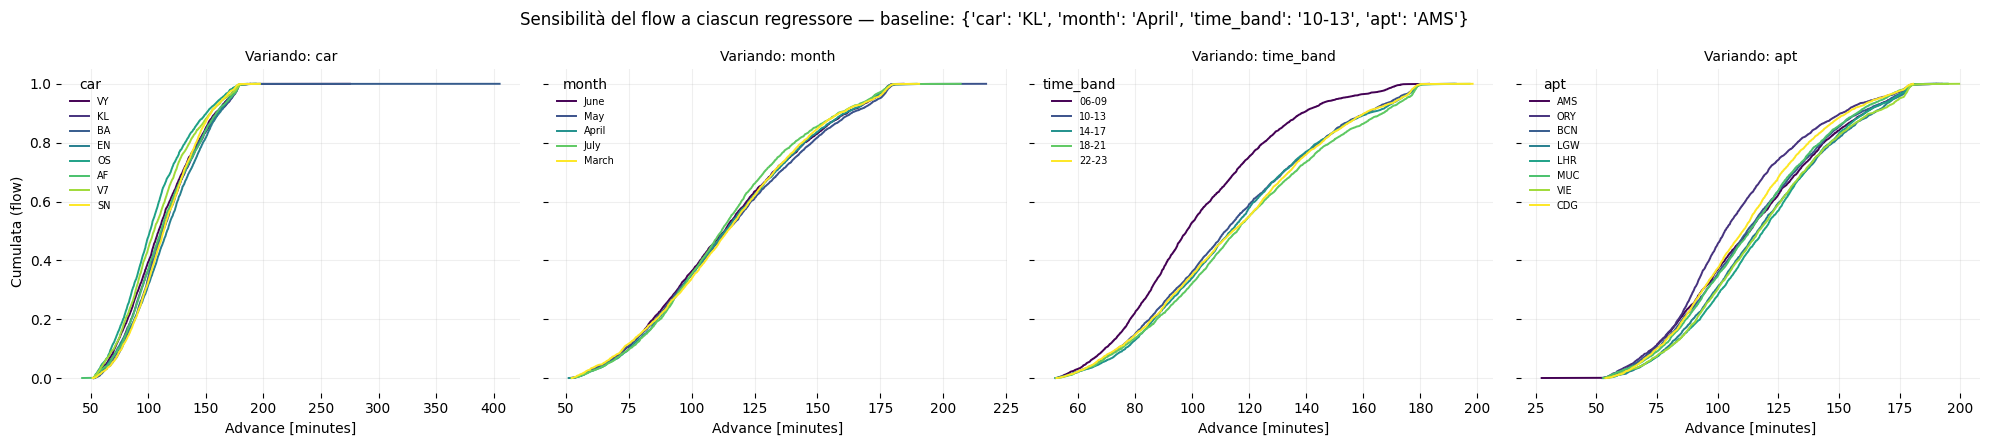

In [51]:
TIME_BAND_ORDER = ["00-05", "06-09", "10-13", "14-17", "18-21", "22-23"]
BASE_COMBO = dict(zip(
    cat_cols,
    train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()
))

TOP_N = 8  # valori più frequenti da confrontare per categoria, altrimenti apt/car sono illeggibili

fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4.5), sharey=True)

for ax, cat in zip(axes, cat_cols):
    if cat == "time_band":
        top_values = [v for v in TIME_BAND_ORDER if v in train_df["time_band"].unique()]
    else:
        top_values = (
            train_df.groupby(cat)["flight_key"].nunique()
            .sort_values(ascending=False)
            .head(TOP_N)
            .index
        )

    colors = plt.cm.viridis(np.linspace(0, 1, len(top_values)))

    for value, color in zip(top_values, colors):
        combo = {**BASE_COMBO, cat: value}
        sampled = sample_advance(combo["car"], combo["month"], combo["time_band"], combo["apt"], n_samples=3000)
        s = np.sort(sampled)
        ax.plot(s, np.arange(1, len(s) + 1) / len(s), color=color, linewidth=1.4, label=str(value))

    ax.set_title(f"Variando: {cat}", fontsize=10)
    ax.set_xlabel("Advance [minutes]")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7, title=cat)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel("Cumulata (flow)")
fig.suptitle(f"Sensibilità del flow a ciascun regressore — baseline: {BASE_COMBO}")
plt.tight_layout()

#### save for production

In [52]:
torch.save({
    "embedder_state": embedder.state_dict(),
    "flow_state": flow.state_dict(),
    "code_lookup": code_lookup,
    "cardinalities": cardinalities,
    "cat_cols": cat_cols,
    "log_adv_mean": log_adv_mean,
    "log_adv_std": log_adv_std,
    "embed_dim": embed_dim,
    "transforms": 3,
    "hidden_features": (64, 64),
}, f"data/arrival_flow.pt")

### Allocation

#### single funcs

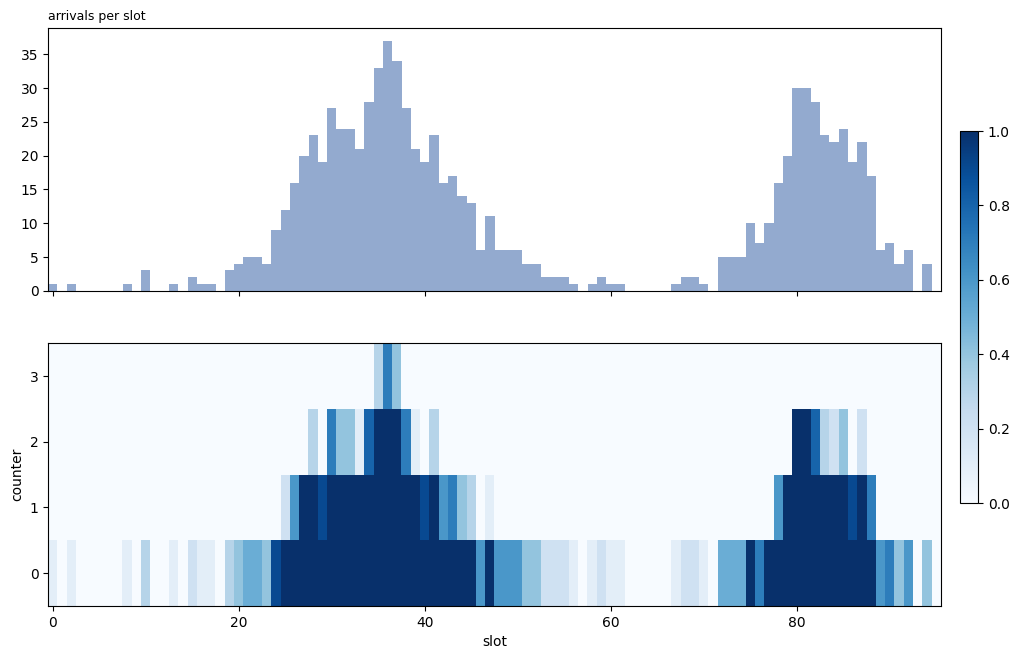

In [14]:
def _synthetic_day(seed, T=96):
    rng = np.random.default_rng(seed)
    t = np.arange(T)
    lam = np.full(T, 0.5)                           # baseline: pax / 15 min
    for _ in range(rng.integers(1, 7)):             # 1-2 peaks
        center, width, height = rng.uniform(10, T - 10), rng.uniform(4, 9), rng.uniform(6, 30)
        lam += height * np.exp(-0.5 * ((t - center) / width) ** 2)
    return rng.poisson(lam).astype(int).tolist()

def arrivals_to_demand_grid(arrivals, mean_processing_rate: float, bin_minutes: float = 15.0):
    """
    Convert arrivals per bin to a demand grid for the coverage DP.
    The demand grid is a 2-D array D of shape (n_counters, T) with values in [0, 1] 
    representing the fraction of each counter-bin that is needed to cover the demand.

    arrivals             : (T,) pax arriving in each bin
    mean_processing_rate : pax per hour processed by one counter
    returns D            : (n_counters, T) float in [0, 1]
    """
    a = np.asarray(arrivals, dtype=np.float64)
    if a.ndim != 1:
        raise ValueError("arrivals must be 1-D (T,)")
    if mean_processing_rate <= 0 or bin_minutes <= 0:
        raise ValueError("mean_processing_rate and bin_minutes must be > 0")
    pax_per_counter_bin = mean_processing_rate * (bin_minutes / 60.0)
    required_exact = a / pax_per_counter_bin
    n_counters = int(np.ceil(required_exact.max() - 1e-9)) if a.size else 0
    if n_counters == 0:
        raise ValueError("no arrivals: the demand grid would be empty")
    D = np.clip(required_exact[None, :] - np.arange(n_counters)[:, None], 0.0, 1.0)
    return D

def plot_grid(arrivals, D):
    T = D.shape[1]
    x = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1]})
    axes[0].bar(x, arrivals, width=1.0, color="#4C72B0", alpha=0.6)
    axes[0].set_title("arrivals per slot", fontsize=9, loc="left")
    im = axes[1].imshow(D, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                        extent=[-0.5, T - 0.5, -0.5, D.shape[0] - 0.5], interpolation="nearest")
    axes[1].set_yticks(range(D.shape[0]))
    axes[1].set_ylabel("counter")
    axes[1].set_xlabel("slot")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    plt.show()

arrivals = _synthetic_day(seed=1)

MEAN_PROCESSING_RATE = 40

grid = arrivals_to_demand_grid(arrivals, MEAN_PROCESSING_RATE, bin_minutes=15)
plot_grid(arrivals, grid)

In [36]:
from app.services.coverage_dp import coverage_report, solve_coverage_batch, allocate_budget, solve_allocated

L_cells, alpha = 12, 0.3
curve = solve_coverage_batch(grid, L_cells, alpha)

K_total = 20
g = allocate_budget(curve, K_total, exact=True)

sols = solve_allocated(grid, L_cells, alpha, g)

print(f"{'ctr':>3} {'k':>3} {'value':>8} | {'inside':>7} {'outside':>8} {'missed':>7}")
for i, s in enumerate(sols):
    assert abs(s.value - (s.inside - alpha * s.outside)) < 1e-9          # objective identity
    assert abs(s.inside + s.missed - grid[i].sum()) < 1e-9                  # all demand is served or missed
    print(f"{i:>3} {g.k[i]:>3} {s.value:>8.2f} | {s.inside:>7.2f} {s.outside:>8.2f} {s.missed:>7.2f}")

ctr   k    value |  inside  outside  missed
  0   8    42.45 |   46.50    13.50    2.50
  1   8    25.47 |   27.90     8.10    0.00
  2   4     6.32 |   10.40    13.60    0.30
  3   0     0.00 |    0.00     0.00    1.40


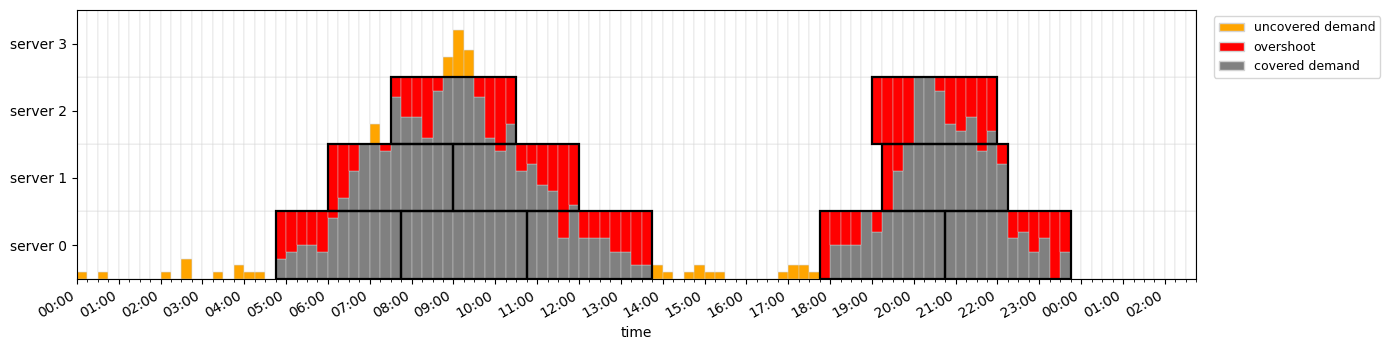

In [37]:
def plot_grid_overlay(grid, alloc, time_values, L=None):

    import matplotlib.dates as mdates
    from matplotlib.patches import Patch, Rectangle

    D = np.asarray(grid, dtype=np.float64)
    if isinstance(alloc, (list, tuple)):                     # list of Solution
        cov = np.vstack([np.asarray(s.coverage, dtype=bool) for s in alloc])
    else:                                                    # bool matrix (n_rows, T)
        cov = np.asarray(alloc, dtype=bool)
    if cov.shape[0] != D.shape[0] or cov.shape[1] < D.shape[1]:
        raise ValueError(f"alloc shape {cov.shape} incompatible with grid shape {D.shape}")
    real_bins = D.shape[1]
    extra = cov.shape[1] - real_bins                         # overhang slots after the end of the day
    if extra:
        D = np.pad(D, ((0, 0), (0, extra)))

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape

    bin_minutes = (
        (time_values.iloc[1] - time_values.iloc[0]).total_seconds() / 60
        if len(time_values) > 1 else 15
    )

    if extra and len(time_values) == real_bins:              # extend the time axis over the overhang
        more = time_values.iloc[-1] + pd.to_timedelta(np.arange(1, extra + 1) * bin_minutes, unit="min")
        time_values = pd.concat([time_values, pd.Series(more)], ignore_index=True)
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    x0 = mdates.date2num(time_values)                        # left edge of each bin
    width = bin_minutes / (24 * 60)                          # bin width in matplotlib date units
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)

    fig, ax = plt.subplots(figsize=(14, 0.4 * n_rows + 2))
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        # bottom part: demand  (grey if covered, orange if not)
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        # top part: capacity not needed  (red if covered = waste, white if not)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)

    # outlined rectangle per shift block
    if isinstance(alloc, (list, tuple)) and L is not None:
        blocks = [(c, int(s0), int(L)) for c, sol in enumerate(alloc) for s0 in sol.starts]

    for c, s0, ln in blocks:
        ax.add_patch(Rectangle((x0[s0], c), ln * width, 1, fill=False,
                               edgecolor="black", linewidth=1.6, zorder=3))
        
    ax.set_xlim(x0[0], x0[-1] + width)
    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([f"server {y}" for y in range(n_rows)])

    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.set_xlabel("time")

    legend_handles = [
        Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered demand"),
        Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
        Patch(facecolor=GREY, edgecolor="lightgray", label="covered demand"),
    ]
    ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

time_values = pd.date_range("2026-01-01 00:00", periods=grid.shape[1], freq=f"15min")
plot_grid_overlay(grid, sols, time_values, L=L_cells)

In [38]:
rep = coverage_report(grid, sols, L_cells, time_values)

rep.total

n_blocks          10.000000
demand            89.000000
covered_demand    84.800000
missed_demand      4.200000
idle_capacity     35.200000
coverage           0.952809
dtype: float64

#### multiple lengths L

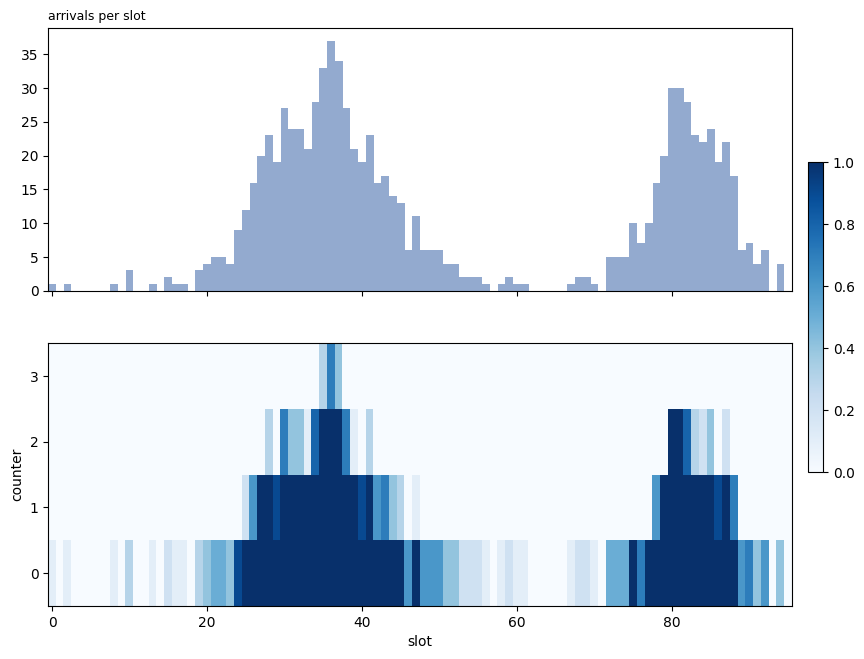

In [2]:
def _synthetic_day(seed, T=96):
    rng = np.random.default_rng(seed)
    t = np.arange(T)
    lam = np.full(T, 0.5)                           # baseline: pax / 15 min
    for _ in range(rng.integers(1, 7)):             # 1-2 peaks
        center, width, height = rng.uniform(10, T - 10), rng.uniform(4, 9), rng.uniform(6, 30)
        lam += height * np.exp(-0.5 * ((t - center) / width) ** 2)
    return rng.poisson(lam).astype(int).tolist()

def arrivals_to_demand_grid(arrivals, mean_processing_rate: float, bin_minutes: float = 15.0):
    """
    Convert arrivals per bin to a demand grid for the coverage DP.
    The demand grid is a 2-D array D of shape (n_counters, T) with values in [0, 1] 
    representing the fraction of each counter-bin that is needed to cover the demand.

    arrivals             : (T,) pax arriving in each bin
    mean_processing_rate : pax per hour processed by one counter
    returns D            : (n_counters, T) float in [0, 1]
    """
    a = np.asarray(arrivals, dtype=np.float64)
    if a.ndim != 1:
        raise ValueError("arrivals must be 1-D (T,)")
    if mean_processing_rate <= 0 or bin_minutes <= 0:
        raise ValueError("mean_processing_rate and bin_minutes must be > 0")
    pax_per_counter_bin = mean_processing_rate * (bin_minutes / 60.0)
    required_exact = a / pax_per_counter_bin
    n_counters = int(np.ceil(required_exact.max() - 1e-9)) if a.size else 0
    if n_counters == 0:
        raise ValueError("no arrivals: the demand grid would be empty")
    D = np.clip(required_exact[None, :] - np.arange(n_counters)[:, None], 0.0, 1.0)
    return D

def plot_grid(arrivals, D):
    T = D.shape[1]
    x = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1]})
    axes[0].bar(x, arrivals, width=1.0, color="#4C72B0", alpha=0.6)
    axes[0].set_title("arrivals per slot", fontsize=9, loc="left")
    im = axes[1].imshow(D, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                        extent=[-0.5, T - 0.5, -0.5, D.shape[0] - 0.5], interpolation="nearest")
    axes[1].set_yticks(range(D.shape[0]))
    axes[1].set_ylabel("counter")
    axes[1].set_xlabel("slot")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    plt.show()

arrivals = _synthetic_day(seed=1)

MEAN_PROCESSING_RATE = 40

grid = arrivals_to_demand_grid(arrivals, MEAN_PROCESSING_RATE, bin_minutes=15)
plot_grid(arrivals, grid)

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Rectangle, Patch


def plot_allocation_multi(grid, sols, time_values, alpha, row_labels=None):
    """
    grid        : (n_rows, T) demand grid in [0, 1]
    sols        : list of MultiSolution, one per row that has a server (fewer than n_rows is fine)
    time_values : (T,) bin start times (regular step)
    alpha       : alpha used by the solver (for the objective in the title)
    row_labels  : names of the rows with a server (default 1..len(sols)); the other rows are "no server"
    """
    D = np.asarray(grid, dtype=np.float64)
    n_rows, T = D.shape
    if len(sols) > n_rows:
        raise ValueError(f"{len(sols)} solutions for {n_rows} rows")

    # bins after the end of the day (overhang): same length as the solutions' coverage
    T_ext = max([T] + [len(s.coverage) for s in sols])
    tv = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    step = tv.iloc[1] - tv.iloc[0]
    tv_ext = pd.DatetimeIndex(tv.iloc[0] + step * np.arange(T_ext))
    D = np.pad(D, ((0, 0), (0, T_ext - T)))
    cov = np.zeros(D.shape, dtype=bool)
    blocks = []                                           # (row, start_dt, end_dt)
    for c, sol in enumerate(sols):
        cov[c, :len(sol.coverage)] = sol.coverage
        for s, l in zip(sol.starts, sol.lengths):
            blocks.append((c, tv_ext[int(s)], tv_ext[int(s)] + int(l) * step))

    total = float(D.sum())
    C = float(D[cov].sum())
    I = float((1.0 - D)[cov].sum())
    obj, coverage = C - alpha * I, (C / total if total > 0 else 1.0)

    labels = list(row_labels) if row_labels is not None else list(range(1, len(sols) + 1))
    x0 = mdates.date2num(tv_ext)                          # left edge of each bin
    width = step.total_seconds() / 86400                  # bin width in matplotlib date units
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)

    fig, ax = plt.subplots(figsize=(10, 0.4 * n_rows + 1))
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)

    multi_length = len({int(l) for s in sols for l in s.lengths}) > 1
    for c, start, end in blocks:
        xs, xe = mdates.date2num(start), mdates.date2num(end)
        ax.add_patch(Rectangle((xs, c), xe - xs, 1, fill=False, edgecolor="black", linewidth=1.6, zorder=3))
        if multi_length:                                  # durata scritta dentro il blocco
            h = (end - start).total_seconds() / 3600
            ax.text((xs + xe) / 2, c + 0.5, f"{h:g}h", ha="center", va="center", fontsize=7, zorder=4)

    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([f"server {labels[c]}" if c < len(sols) else "no server" for c in range(n_rows)])
    ax.legend(handles=[Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered"),
                       Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
                       Patch(facecolor=GREY, edgecolor="lightgray", label="covered")],
              loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)

    ax.set_xlim(x0[0], x0[-1] + width)
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.set_axisbelow(True)
    ax.grid(axis="x", which="major", linestyle="-", alpha=0.5, zorder=1)

    hours = pd.Series([(e - s).total_seconds() / 3600 for _, s, e in blocks]).round(2)
    shifts = " + ".join(f"{n}×{h:g}h" for h, n in hours.value_counts().sort_index().items()) or "no shifts"
    fig.suptitle(f"shifts: {shifts}  |  alpha = {alpha:g}  |  {len(blocks)} blocks  |  "
                 f"obj = {obj:.2f}  |  coverage = {coverage:.1%}")
    fig.autofmt_xdate(rotation=90)
    fig.tight_layout()
    plt.show()

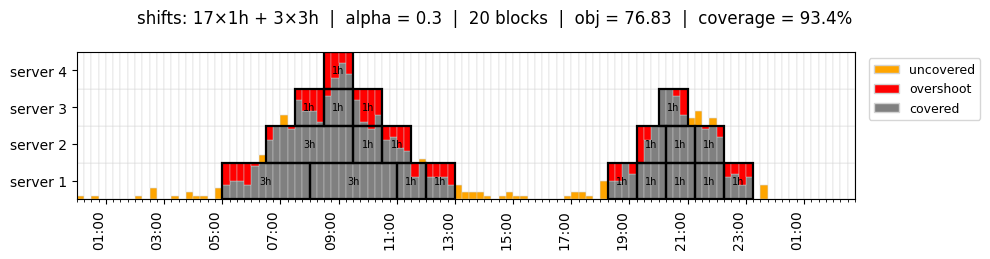

In [4]:
from app.services.coverage_dp import coverage_report_multi, solve_coverage_batch_multi, allocate_budget_multi, solve_allocated_multi, allocate_milp

lengths=[12, 4]
alpha=0.3
K_total= 20
length_totals={12:3}

curves = solve_coverage_batch_multi(grid, lengths, alpha)
alloc = allocate_budget_multi(curves, lengths, K_total=K_total, length_totals=length_totals)
sols = solve_allocated_multi(grid, alpha, alloc)

time_values = pd.date_range("2026-06-01 00:00", periods=grid.shape[1], freq="15min")

report = coverage_report_multi(grid, sols, time_values=time_values, alpha=alpha)

plot_allocation_multi(grid, sols, time_values, alpha)

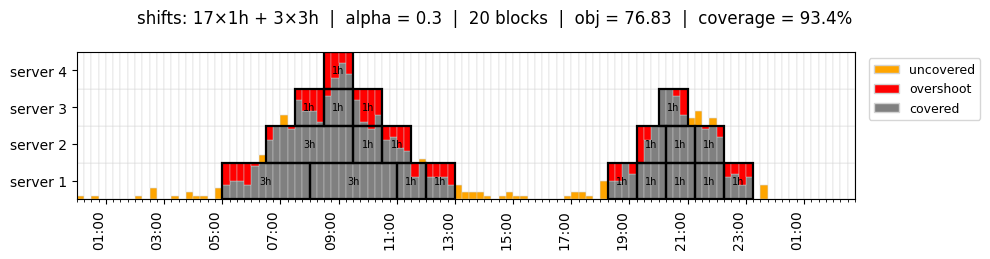

In [6]:
alloc = allocate_milp(curves, lengths, K_total=K_total, length_per_day=length_totals)
sols = solve_allocated_multi(grid, alpha, alloc)

time_values = pd.date_range("2026-06-01 00:00", periods=grid.shape[1], freq="15min")

report = coverage_report_multi(grid, sols, time_values=time_values, alpha=alpha)

plot_allocation_multi(grid, sols, time_values, alpha)

#### class and synthetic arrivals

In [2]:
def make_synthetic_arrivals(
    pax_per_server_bin: float,
    peak_servers=(4.2, 3.4),
    peak_hours=(8.0, 17.5),
    widths_h=(1.6, 2.0),
    base_servers=0.15,
    day="2026-03-02",
    bin_minutes=15,
    seed=0,
) -> pd.Series:
    T = 24 * 60 // bin_minutes
    t_h = (np.arange(T) + 0.5) * bin_minutes / 60                      # centro del bin, in ore
    servers_needed = np.full(T, base_servers)
    for hour, width, amp in zip(peak_hours, widths_h, peak_servers):
        servers_needed += amp * np.exp(-0.5 * ((t_h - hour) / width) ** 2)
    rng = np.random.default_rng(seed)
    index = pd.date_range(day, periods=T, freq=f"{bin_minutes}min")
    return pd.Series(rng.poisson(servers_needed * pax_per_server_bin).astype(float),
                     index=index, name="arrivals")

BIN_MINUTES = 15
arrivals = make_synthetic_arrivals(30, seed=1)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    7: {'label': '7', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    8: {'label': '8', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-19 14:15:31,471 | INFO | app.services.security_class | [SecurityPlanner] Launching allocation DP: L=3.00h, alpha=0.30


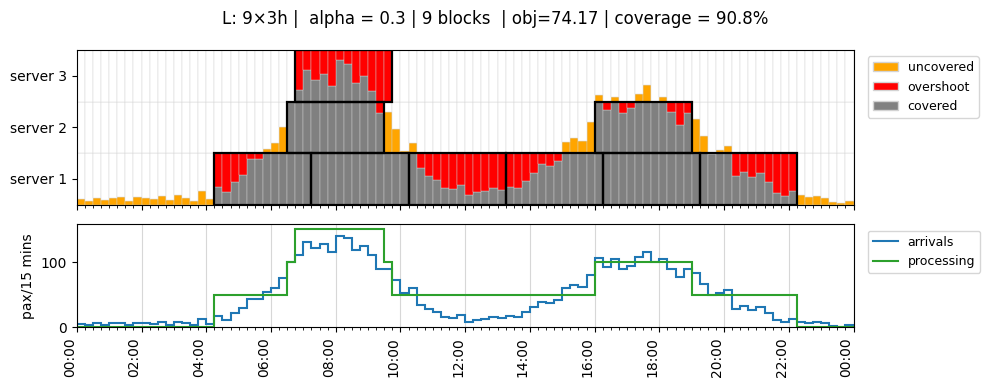

In [3]:
planner = security_class.SecurityPlanner(arrivals, server_registry)

res = planner.run(L=3, alpha=0.3, K_total=1000)

plotutils.plot_allocation(res)

2026-10-19 14:15:32,052 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[1.0, 3.0] h, alpha=0.30


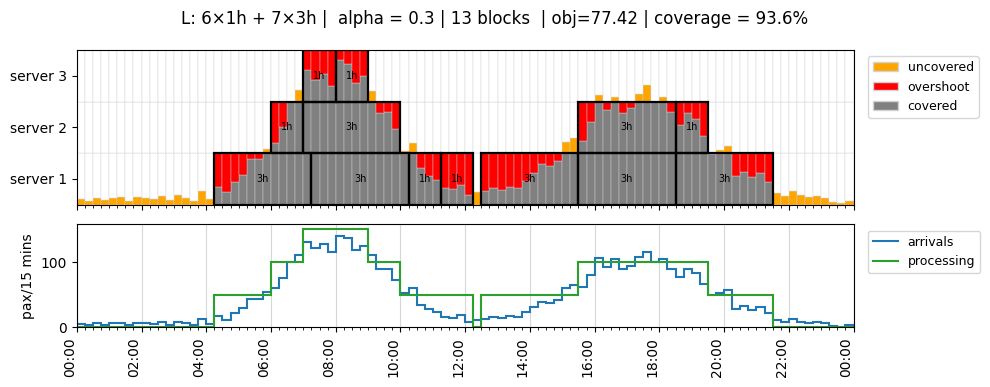

In [4]:
res = planner.run_multi(lengths=[1, 3], alpha=0.3, K_total=1000)

plotutils.plot_allocation(res)

#### from schedule (single day)

In [65]:
date=dt.datetime(2026, 6, 1)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-19 17:47:53,684 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


2026-10-19 17:47:53,708 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[3.0, 4.0, 6.0] h, alpha=0.50


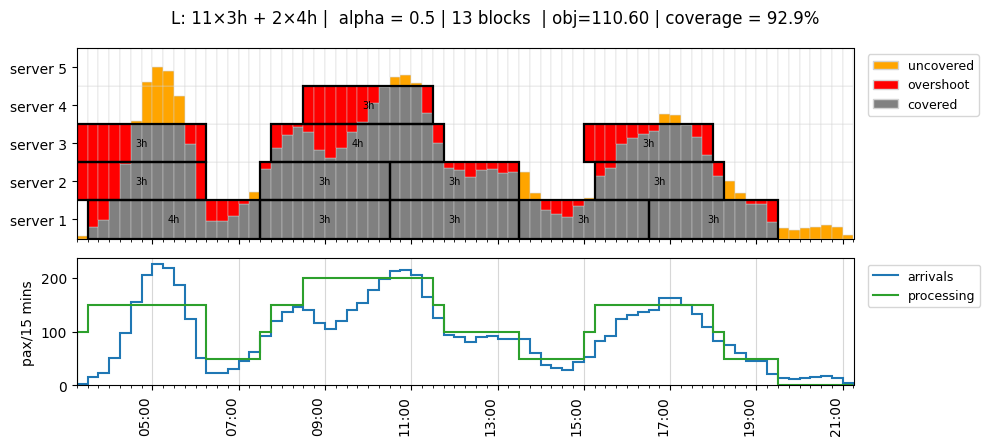

In [66]:
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

lengths=[6, 4, 3]
length_totals={6:3}
K_total=1000

res = planner.run_multi(lengths=lengths, length_totals=length_totals, alpha=0.5, K_total=K_total)
plotutils.plot_allocation(res)

2026-10-19 17:48:47,731 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 30 total tasks, 4 workers


Avg qtime 0    4.79176
Name: qtime_mean, dtype: float64


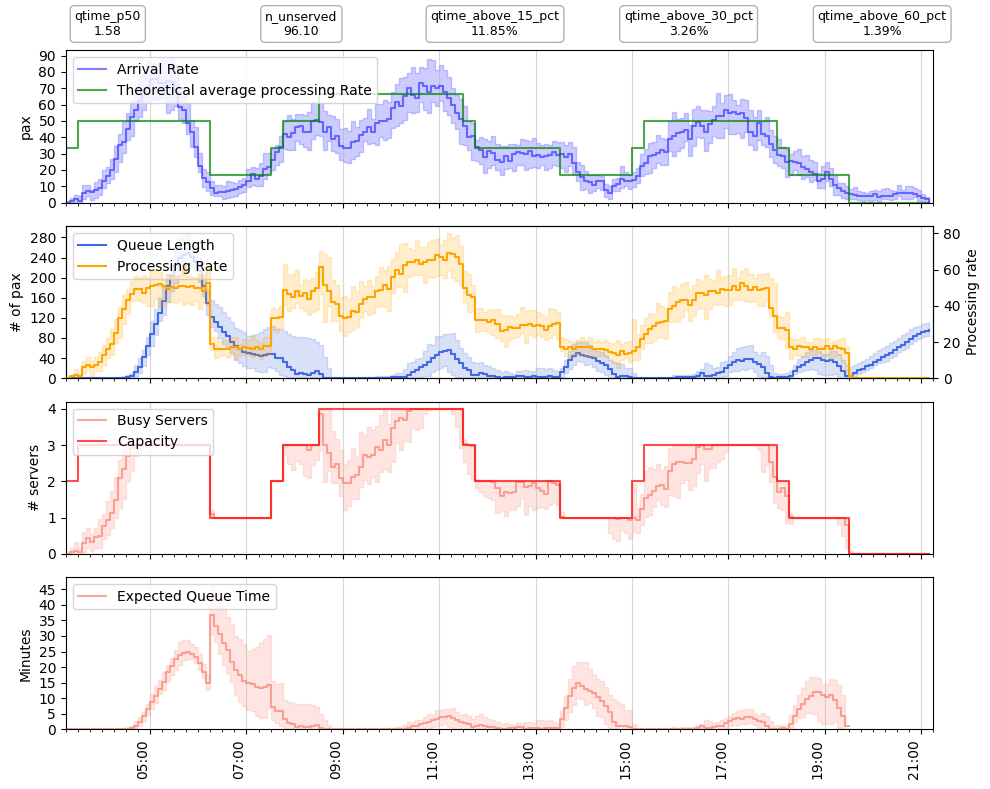

In [70]:
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=30, n_workers=4, timebin=5, base_seed=base_seed)
print("Avg qtime", sim_results.df_kpis.qtime_mean)
plotutils.plot_simulation(sim_results.df_timeline, sim_results.df_kpis)

#### from schedule (multiple day)

In [2]:
dates = pd.date_range("2026-06-01", periods=5, freq="D")

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"].isin(dates)].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)
arrivals= security_class.expected_arrivals(flight_demand)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-19 16:10:37,047 | WARNING | app.services.preprocessing | More than 10% of flights (54/306) fall back to the unknown arrival sampler. Check the arrival model coverage.


In [3]:
lengths=[4, 1.5]
alpha=0.7
K_total=1000
length_per_day={4:10, 1.5:15}

planner = security_class.MultiDayPlanner(arrivals, server_registry)

res = planner.run(lengths=lengths, alpha=0.5, K_total=K_total, length_per_day=length_per_day)

2026-10-19 16:10:37,093 | INFO | app.services.security_class | [MultiDayPlanner] curves: 5 days x 5 layers, lengths=[1.5, 4.0] h, alpha=0.50


In [4]:
planner.report_by_day()

,n_blocks,demand,covered_demand,missed_demand,idle_capacity,coverage,objective,n_blocks_6,n_blocks_16
day,,,,,,,,,
2026-06-01,16,138.16,129.714531,8.445469,16.285469,0.938872,121.571797,11,5
2026-06-02,17,129.90,122.866786,7.033214,19.133214,0.945857,113.300179,13,4
2026-06-03,16,117.02,109.130430,7.889570,16.869570,0.932579,100.695645,13,3
2026-06-04,16,128.78,119.050174,9.729826,16.949826,0.924446,110.575261,12,4
2026-06-05,18,142.04,134.869670,7.170330,23.130330,0.949519,123.304505,13,5


2026-06-01


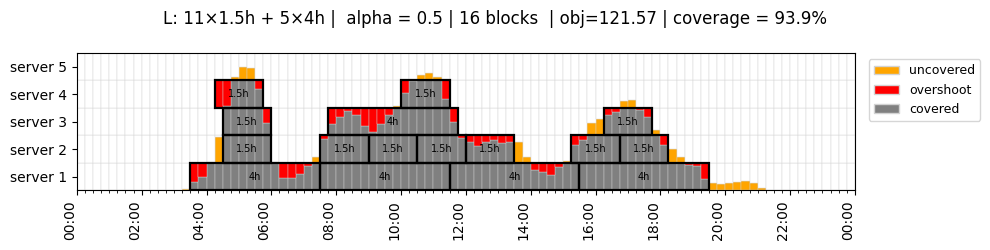

2026-06-02


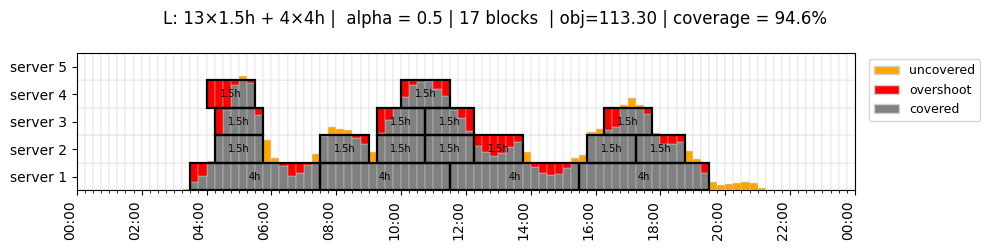

2026-06-03


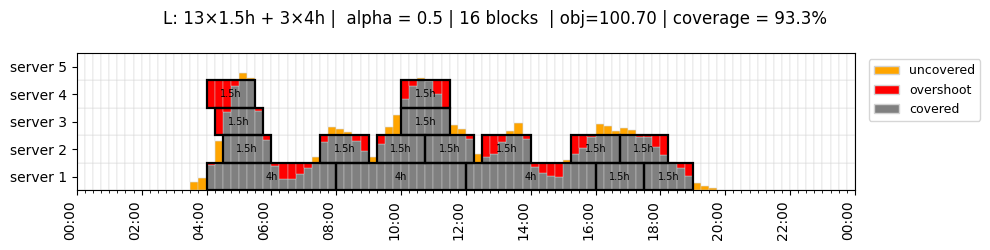

2026-06-04


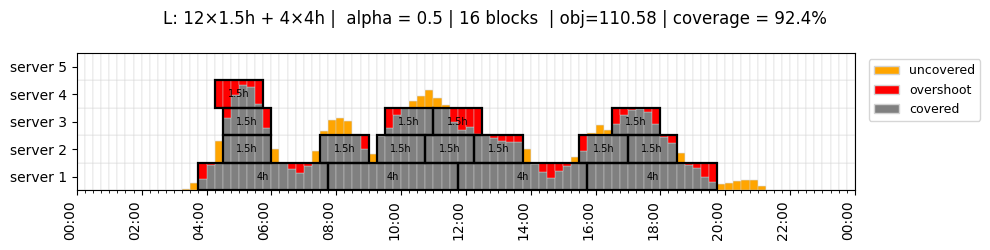

2026-06-05


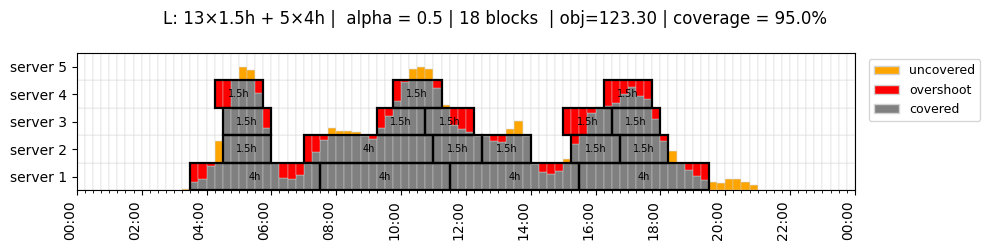

In [5]:
for n, r in enumerate(res.day_results):
    print(planner.days[n].date())
    plotutils.plot_allocation(r, show_second=False)

#### Evaluation on random movements (single day)

2026-10-20 16:44:24,776 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-10-20 16:44:24,782 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, alpha=4.00


running baseline


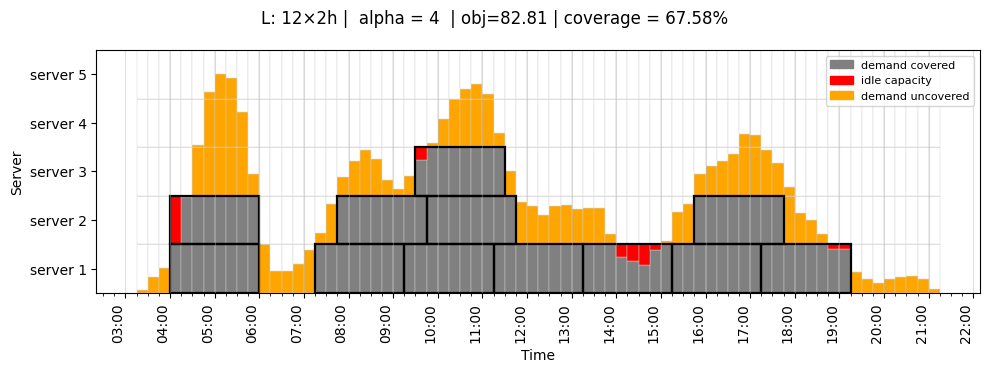

In [2]:
date=dt.datetime(2026, 6, 1)
alpha = 4

lengths=[2]
length_totals={2:100}
K_total=1000

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

print("running baseline")
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)
res = planner.run_multi(lengths=lengths, length_totals=length_totals, alpha=alpha, K_total=K_total)
plotutils.plot_allocation(res, show_second=False)

In [3]:
from app.services.perturbation import *
from app.services.simulation_batch import simulate_kpis

alphas = [1.1, 1.3]
max_moves = 5
n_reps = 3
T = planner.demand_grid.shape[1]
out_path = os.path.join("data", f"perturbation_alpha2_{date.date()}.xlsx")

# resume: alphas already in the file are skipped; the file is saved after every alpha
df_prev = pd.read_excel(out_path) if os.path.exists(out_path) else pd.DataFrame()
rows = df_prev.to_dict("records")
done = {round(a, 6) for a in df_prev["alpha"]} if len(df_prev) else set()
rep = int(df_prev["rep"].max()) + 1 if len(df_prev) else 0       # global, unique across alphas

for alpha_i in alphas:
    if round(alpha_i, 6) in done:
        print(f"alpha={alpha_i}: already in {out_path}, skipped")
        continue
    res_a = get_res(alpha_i)
    base = schedule_to_blocks(planner, res_a)
    n_blocks = sum(len(v) for v in base.values())
    rng = np.random.default_rng(42)

    # 1) all schedules of this alpha first (schedule 0 = baseline)
    schedules, seen = [(base, [])], {blocks_to_json(base)}
    for _ in range(20 * n_reps):
        if len(schedules) > n_reps:
            break
        k = int(rng.integers(1, max_moves + 1))
        blocks, moves = perturb_blocks(base, T, k, rng)
        key = blocks_to_json(blocks)
        if key in seen:
            continue
        seen.add(key)
        schedules.append((blocks, moves))
    print(f"alpha={alpha_i}: {len(schedules) - 1} perturbed schedules")
    plotutils.plot_allocation(res_with_blocks(planner, res_a, base), show_second=False)

    # 2) all simulations in one pool (batches only for progress / memory)
    intervals_list = [utils.server_schedule_to_intervals(blocks_to_schedule(planner, b)) for b, _ in schedules]
    batch = 100
    parts = []
    for i0 in range(0, len(intervals_list), batch):
        print(f"alpha={alpha_i}: simulating schedules {i0}-{min(i0 + batch, len(intervals_list)) - 1}")
        parts.append(simulate_kpis(flight_demand, intervals_list[i0:i0 + batch], server_registry,
                                   n_scenarios=50, n_workers=os.cpu_count(), timebin=15, base_seed=base_seed))
    kpis = pd.concat(parts, ignore_index=True)

    # 3) rows
    for rep_alpha, (blocks, moves) in enumerate(schedules):
        k = kpis.iloc[rep_alpha]
        rows.append(dict(
            date=date, lengths=str(lengths), length_totals=str(length_totals), K_total=K_total,
            alpha=alpha_i, n_blocks=n_blocks, rep=rep, rep_alpha=rep_alpha, is_baseline=(rep_alpha == 0),
            n_moves=len(moves),
            **coverage_from_blocks(planner, res_a, blocks),
            qtime_mean=k["qtime_mean"], n_unserved=k["n_unserved"], qtime_above_30_pct=k["qtime_above_30_pct"],
            moves=json.dumps(moves), blocks=blocks_to_json(blocks)))
        rep += 1

    pd.DataFrame(rows).to_excel(out_path, index=False)
    print(f"alpha={alpha_i}: saved")

df_pert = pd.DataFrame(rows)

NameError: name 'get_res' is not defined

In [4]:
df_pert = pd.read_excel(os.path.join("data", f"perturbation_alpha_{date.date()}.xlsx"))
df_pert

,date,lengths,length_totals,K_total,alpha,n_blocks,rep,rep_alpha,is_baseline,n_moves,covered_demand,idle_capacity,coverage,objective,qtime_mean,n_unserved,qtime_above_30_pct,moves,blocks
0,2026-06-01,[2],{2: 100},1000,0.6,20,0,0,True,0,132.747370,27.252630,0.960823,116.395792,1.900419,91.48,1.324262,[],"{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
1,2026-06-01,[2],{2: 100},1000,0.6,20,1,1,False,1,131.747370,28.252630,0.953585,114.795792,1.902845,91.48,1.324262,"[[""3"", 2, 1]]","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
2,2026-06-01,[2],{2: 100},1000,0.6,20,2,2,False,4,129.753107,30.246893,0.939151,111.604971,1.908829,91.48,1.324262,"[[""2"", 1, -1], [""3"", 2, 1], [""3"", 3, 1], [""2"",...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
3,2026-06-01,[2],{2: 100},1000,0.6,20,3,3,False,5,129.916818,30.083182,0.940336,111.866909,2.736298,76.72,1.110596,"[[""4"", 1, -1], [""4"", 0, -1], [""3"", 1, -1], [""3...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
4,2026-06-01,[2],{2: 100},1000,0.6,20,4,4,False,4,129.829129,30.170871,0.939701,111.726606,3.058397,91.48,1.324262,"[[""3"", 3, -1], [""2"", 0, 1], [""2"", 5, 1], [""2"",...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
803,2026-06-01,[2],{2: 100},1000,2.3,14,803,96,False,2,105.127406,6.872594,0.760911,89.320440,116.127756,1303.82,91.971627,"[[""3"", 1, -1], [""1"", 6, 1]]","{""1"": [[3, 8], [15, 8], [23, 8], [31, 8], [39,..."
804,2026-06-01,[2],{2: 100},1000,2.3,14,804,97,False,2,104.678851,7.321149,0.757664,87.840208,118.165370,1331.42,91.357556,"[[""1"", 0, -1], [""2"", 1, -1]]","{""1"": [[2, 8], [15, 8], [23, 8], [31, 8], [39,..."
805,2026-06-01,[2],{2: 100},1000,2.3,14,805,98,False,4,104.789348,7.210652,0.758464,88.204848,117.762955,1328.98,91.352345,"[[""1"", 1, -1], [""2"", 4, 1], [""2"", 1, -1], [""2""...","{""1"": [[3, 8], [14, 8], [23, 8], [31, 8], [39,..."
806,2026-06-01,[2],{2: 100},1000,2.3,14,806,99,False,2,105.646446,6.353554,0.764667,91.033272,116.127756,1303.82,91.971627,"[[""1"", 6, 1], [""2"", 4, -1]]","{""1"": [[3, 8], [15, 8], [23, 8], [31, 8], [39,..."


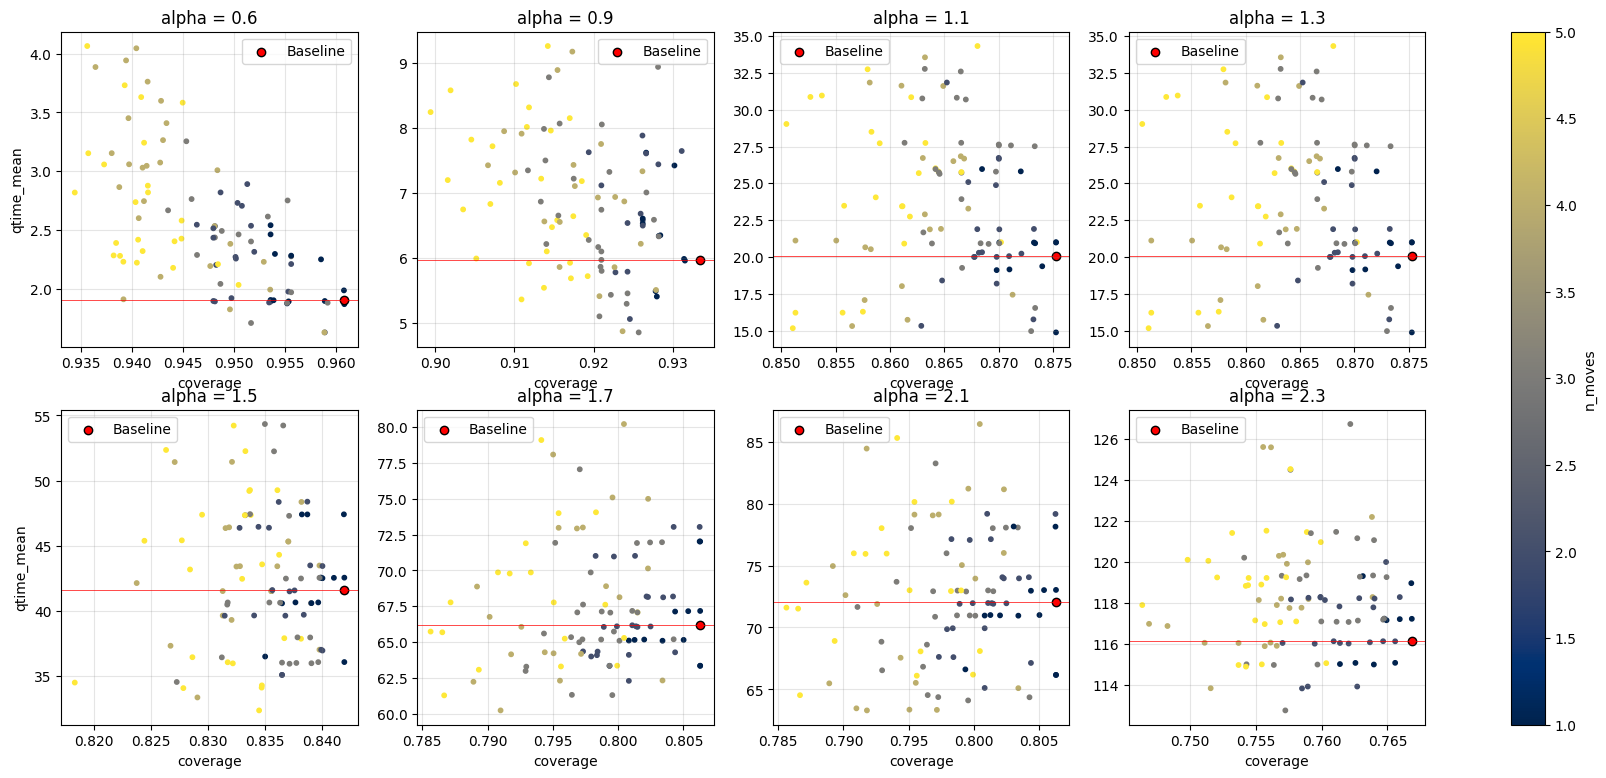

In [5]:
import math

x, y, c = "coverage", "qtime_mean", "n_moves"
max_cols = 4
alphas_in = sorted(df_pert["alpha"].unique())
n_rows = math.ceil(len(alphas_in) / max_cols)
n_cols = min(len(alphas_in), max_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows), squeeze=False)
norm = plt.Normalize(vmin=1, vmax=df_pert[c].max())
flat = axes.ravel()
for ax, a in zip(flat, alphas_in):
    d = df_pert[df_pert["alpha"] == a]
    b = d[d["is_baseline"]].iloc[0]
    sc = ax.scatter(d[x], d[y], c=d[c], cmap="cividis", norm=norm, s=10)
    ax.scatter(b[x], b[y], color="red", edgecolor="black", label="Baseline")
    ax.axhline(b[y], color="red", linewidth=0.5)
    ax.set_title(f"alpha = {a}")
    ax.set_xlabel(x)
    ax.grid(color="gray", alpha=0.2)
    ax.legend()
for ax in flat[len(alphas_in):]:
    ax.set_visible(False)                    
for ax in axes[:, 0]:
    ax.set_ylabel(y)
fig.colorbar(sc, ax=flat[:len(alphas_in)].tolist(), label=c)
plt.show()

In [10]:
df_pert

,date,lengths,length_totals,K_total,alpha,n_blocks,rep,rep_alpha,is_baseline,n_moves,covered_demand,idle_capacity,coverage,objective,qtime_mean,n_unserved,qtime_above_30_pct,moves,blocks
0,2026-06-01,[2],{2: 100},1000,0.6,20,0,0,True,0,132.747370,27.252630,0.960823,116.395792,1.900419,91.48,1.324262,[],"{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
1,2026-06-01,[2],{2: 100},1000,0.6,20,1,1,False,1,131.747370,28.252630,0.953585,114.795792,1.902845,91.48,1.324262,"[[""3"", 2, 1]]","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
2,2026-06-01,[2],{2: 100},1000,0.6,20,2,2,False,4,129.753107,30.246893,0.939151,111.604971,1.908829,91.48,1.324262,"[[""2"", 1, -1], [""3"", 2, 1], [""3"", 3, 1], [""2"",...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
3,2026-06-01,[2],{2: 100},1000,0.6,20,3,3,False,5,129.916818,30.083182,0.940336,111.866909,2.736298,76.72,1.110596,"[[""4"", 1, -1], [""4"", 0, -1], [""3"", 1, -1], [""3...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
4,2026-06-01,[2],{2: 100},1000,0.6,20,4,4,False,4,129.829129,30.170871,0.939701,111.726606,3.058397,91.48,1.324262,"[[""3"", 3, -1], [""2"", 0, 1], [""2"", 5, 1], [""2"",...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
803,2026-06-01,[2],{2: 100},1000,2.3,14,803,96,False,2,105.127406,6.872594,0.760911,89.320440,116.127756,1303.82,91.971627,"[[""3"", 1, -1], [""1"", 6, 1]]","{""1"": [[3, 8], [15, 8], [23, 8], [31, 8], [39,..."
804,2026-06-01,[2],{2: 100},1000,2.3,14,804,97,False,2,104.678851,7.321149,0.757664,87.840208,118.165370,1331.42,91.357556,"[[""1"", 0, -1], [""2"", 1, -1]]","{""1"": [[2, 8], [15, 8], [23, 8], [31, 8], [39,..."
805,2026-06-01,[2],{2: 100},1000,2.3,14,805,98,False,4,104.789348,7.210652,0.758464,88.204848,117.762955,1328.98,91.352345,"[[""1"", 1, -1], [""2"", 4, 1], [""2"", 1, -1], [""2""...","{""1"": [[3, 8], [14, 8], [23, 8], [31, 8], [39,..."
806,2026-06-01,[2],{2: 100},1000,2.3,14,806,99,False,2,105.646446,6.353554,0.764667,91.033272,116.127756,1303.82,91.971627,"[[""1"", 6, 1], [""2"", 4, -1]]","{""1"": [[3, 8], [15, 8], [23, 8], [31, 8], [39,..."


In [20]:
r_a= df_pert[(df_pert["alpha"] == 0.9) & (df_pert["rep_alpha"] == 0)].iloc[0]
r_b= df_pert[(df_pert["alpha"] == 0.9) & (df_pert["rep_alpha"] == 1)].iloc[0]

diff_schedules(df_pert, rep_a=r_a, rep_b=r_b, planner=planner)

rep 101 (a)  vs  rep 102 (b): 1 moved, 0 removed, 0 added
                           a         b   delta
coverage              0.9334    0.9278 -0.0056
objective           108.2278  106.7537 -1.4741
idle_capacity        23.0380   23.8138  0.7759
qtime_mean            5.9710    5.4929 -0.4781
n_unserved           91.4800   91.4800  0.0000
qtime_above_30_pct    5.2959    5.2221 -0.0738


,lane,block,kind,length,start_a,start_b,shift,time_a,time_b
0,3,1,moved,8,18,17,-1,07:45-09:45,07:30-09:30


In [ ]:
def fluid_qtime(planner, blocks, refine=15):
    """Deterministic FIFO fluid queue of a single-day schedule, arrivals and capacity uniform inside each slot
    (refine = sub-steps per slot). Returns (mean wait in minutes of the passengers served by the end of the day,
    passengers still in queue at the end)."""
    a = planner.arrivals.to_numpy(float)                   # pax per slot
    T = len(a)
    cap = np.zeros(T)                                      # pax served per slot by the open lanes
    for label, bl in blocks.items():
        for s, l in bl:
            cap[s:min(s + l, T)] += planner.rate_by_label[label]      # rate_by_label is already pax per bin
    a_f, cap_f = np.repeat(a / refine, refine), np.repeat(cap / refine, refine)
    n = len(a_f)
    q, dep = 0.0, np.zeros(n)
    for t in range(n):
        dep[t] = min(q + a_f[t], cap_f[t])
        q += a_f[t] - dep[t]        
    A, D = np.cumsum(a_f), np.cumsum(dep)
    tau = np.searchsorted(D, A - 1e-9, side="left")        # first sub-step by which all arrivals up to t have left
    served = tau < n
    wait = (tau - np.arange(n))[served] * (planner.bin_minutes / refine)
    mean_wait = float((a_f[served] * wait).sum() / a_f[served].sum()) if a_f[served].sum() > 0 else 0.0
    return mean_wait, float(a_f[~served].sum())

In [45]:
res_f = [fluid_qtime(planner, parse_blocks(b)) for b in df_pert["blocks"]]
df_pert["q_fluid"] = [r[0] for r in res_f]
df_pert["unserved_fluid"] = [r[1] for r in res_f]
df_pert

,date,lengths,length_totals,K_total,alpha,n_blocks,rep,rep_alpha,is_baseline,n_moves,...,idle_capacity,coverage,objective,qtime_mean,n_unserved,qtime_above_30_pct,moves,blocks,q_fluid,unserved_fluid
0,2026-06-01,[2],{2: 100},1000,0.6,20,0,0,True,0,...,27.252630,0.960823,116.395792,1.900419,91.48,1.324262,[],"{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ...",1.259804,91.24785
1,2026-06-01,[2],{2: 100},1000,0.6,20,1,1,False,1,...,28.252630,0.953585,114.795792,1.902845,91.48,1.324262,"[[""3"", 2, 1]]","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ...",1.283930,91.24785
2,2026-06-01,[2],{2: 100},1000,0.6,20,2,2,False,4,...,30.246893,0.939151,111.604971,1.908829,91.48,1.324262,"[[""2"", 1, -1], [""3"", 2, 1], [""3"", 3, 1], [""2"",...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ...",1.292907,91.24785
3,2026-06-01,[2],{2: 100},1000,0.6,20,3,3,False,5,...,30.083182,0.940336,111.866909,2.736298,76.72,1.110596,"[[""4"", 1, -1], [""4"", 0, -1], [""3"", 1, -1], [""3...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ...",1.907877,77.31150
4,2026-06-01,[2],{2: 100},1000,0.6,20,4,4,False,4,...,30.170871,0.939701,111.726606,3.058397,91.48,1.324262,"[[""3"", 3, -1], [""2"", 0, 1], [""2"", 5, 1], [""2"",...","{""1"": [[1, 8], [9, 8], [17, 8], [25, 8], [33, ...",2.325854,91.24785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
803,2026-06-01,[2],{2: 100},1000,2.3,14,803,96,False,2,...,6.872594,0.760911,89.320440,116.127756,1303.82,91.971627,"[[""3"", 1, -1], [""1"", 6, 1]]","{""1"": [[3, 8], [15, 8], [23, 8], [31, 8], [39,...",117.286163,1316.35833
804,2026-06-01,[2],{2: 100},1000,2.3,14,804,97,False,2,...,7.321149,0.757664,87.840208,118.165370,1331.42,91.357556,"[[""1"", 0, -1], [""2"", 1, -1]]","{""1"": [[2, 8], [15, 8], [23, 8], [31, 8], [39,...",116.423693,1316.35833
805,2026-06-01,[2],{2: 100},1000,2.3,14,805,98,False,4,...,7.210652,0.758464,88.204848,117.762955,1328.98,91.352345,"[[""1"", 1, -1], [""2"", 4, 1], [""2"", 1, -1], [""2""...","{""1"": [[3, 8], [14, 8], [23, 8], [31, 8], [39,...",116.379310,1316.35833
806,2026-06-01,[2],{2: 100},1000,2.3,14,806,99,False,2,...,6.353554,0.764667,91.033272,116.127756,1303.82,91.971627,"[[""1"", 6, 1], [""2"", 4, -1]]","{""1"": [[3, 8], [15, 8], [23, 8], [31, 8], [39,...",117.286163,1316.35833


In [57]:
rows_c = []
for a, g in df_pert.groupby("alpha"):
    rows_c.append(dict(alpha=a,
                       rho_coverage=g["coverage"].corr(g["qtime_mean"], method="spearman"),
                       rho_fluid=g["q_fluid"].corr(g["qtime_mean"], method="spearman"),
                       rho_unserved=g["unserved_fluid"].corr(g["n_unserved"], method="spearman")))
pd.DataFrame(rows_c).set_index("alpha").round(3)

,rho_coverage,rho_fluid,rho_unserved
alpha,,,
0.6,-0.651,0.982,0.982
0.9,-0.345,0.992,0.970
1.1,-0.195,0.995,0.952
1.3,-0.195,0.995,0.952
1.5,-0.037,0.993,0.952
1.7,0.134,0.920,0.937
2.1,0.117,0.992,0.941
2.3,-0.004,0.857,0.376


(0.0, 133.05571258474225)

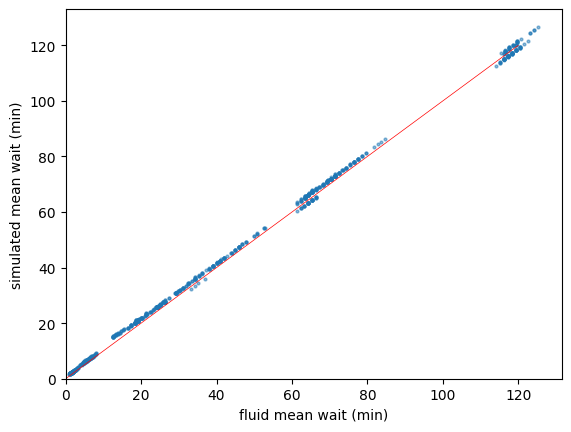

In [50]:

x="q_fluid"
y="qtime_mean"

plt.scatter(df_pert["q_fluid"], df_pert["qtime_mean"], s=4, alpha=0.5)
plt.plot([0, 120], [0, 120], color="red", linewidth=0.5)
plt.xlabel("fluid mean wait (min)")
plt.ylabel("simulated mean wait (min)")
plt.xlim(0,)    
plt.ylim(0,)

In [37]:
rows_c = []
for a, g in df_pert.groupby("alpha"):
    rows_c.append(dict(alpha=a,
                       rho_coverage=g["coverage"].corr(g["qtime_mean"], method="spearman"),
                       rho_fluid=g["q_fluid"].corr(g["qtime_mean"], method="spearman")))
pd.DataFrame(rows_c).set_index("alpha").round(3)

,rho_coverage,rho_fluid
alpha,,
0.6,-0.651,0.733
0.9,-0.345,0.944
1.1,-0.195,0.992
1.3,-0.195,0.992
1.5,-0.037,0.987
1.7,0.134,0.864
2.1,0.117,0.984
2.3,-0.004,0.721


In [31]:
def show_blocks(planner, res):
    """Print the baseline schedule as Python code: copy it, edit it, pass it to run_edit."""
    base = schedule_to_blocks(planner, res)
    t0, step = pd.Timestamp(planner.time_values[0]), planner.bin_duration
    hhmm = lambda s: (t0 + int(s) * step).strftime("%H:%M")
    hours = step.total_seconds() / 3600
    print("blocks = {")
    for lab in res.server_labels:
        bl = base.get(lab, [])
        if not bl:
            print(f"    {lab!r}: [],")
            continue
        print(f"    {lab!r}: [")
        for i, (s, l) in enumerate(bl):
            print(f"        ({s}, {l}),   # {i}: {hhmm(s)}-{hhmm(s + l)}  {l * hours:g}h")
        print("    ],")
    print("}")
    return base


def check_blocks(blocks, labels, T):
    """Validate a hand-edited schedule: known lanes, blocks inside [0, T], no overlap in a lane. Returns it sorted."""
    labels = list(labels)
    unknown = set(blocks) - set(labels)
    if unknown:
        raise ValueError(f"unknown lanes {sorted(unknown)}; lanes are {labels}")
    out = {}
    for lab, bl in blocks.items():
        bl = sorted((int(s), int(l)) for s, l in bl)
        for s, l in bl:
            if l < 1 or s < 0 or s + l > T:
                raise ValueError(f"lane {lab!r}: block (start={s}, length={l}) is outside the day [0, {T}]")
        for (s1, l1), (s2, l2) in zip(bl, bl[1:]):
            if s2 < s1 + l1:
                raise ValueError(f"lane {lab!r}: blocks ({s1}, {l1}) and ({s2}, {l2}) overlap")
        if bl:
            out[lab] = bl
    return out


def run_edit(planner, res, blocks, baseline_row=None, n_scenarios=50, n_workers=4, timebin=15,
             base_seed=base_seed, plot=True):
    """Simulate and plot a hand-edited schedule against the baseline.
    blocks       : {lane: [(start_slot, length_slots), ...]} as printed by show_blocks, edited by hand
    baseline_row : a row of df_pert (e.g. rep=0) with its KPIs; if None only coverage/objective are compared."""
    base = schedule_to_blocks(planner, res)
    T = planner.demand_grid.shape[1]
    blocks = check_blocks(blocks, res.server_labels, T)

    res_i = res_with_blocks(planner, res, blocks)
    if plot:
        print("Baseline")
        plotutils.plot_allocation(res_with_blocks(planner, res, base), show_second=False)
        print("Edited")
        plotutils.plot_allocation(res_i, show_second=False)

    intervals = utils.server_schedule_to_intervals(blocks_to_schedule(planner, blocks))
    sim = security_class.SecuritySimulator(flight_demand=flight_demand, intervals=intervals,
                                           server_registry=server_registry)
    sim_results = sim.run(n_scenarios=n_scenarios, n_workers=n_workers, timebin=timebin, base_seed=base_seed)

    k = sim_results.df_kpis.iloc[0]
    row = pd.Series(dict(rep="edit", blocks=blocks_to_json(blocks), **coverage_from_blocks(planner, res, blocks),
                         qtime_mean=k.qtime_mean, n_unserved=k.n_unserved,
                         qtime_above_30_pct=k.qtime_above_30_pct))
    if baseline_row is None:
        baseline_row = pd.Series(dict(rep="baseline", blocks=blocks_to_json(base),
                                      **coverage_from_blocks(planner, res, base)))
    diff = diff_schedules(None, baseline_row, row, planner=planner)     # what moved + KPI deltas
    return dict(blocks=blocks, res=res_i, sim=sim_results, metrics=row, diff=diff)

In [32]:
base = show_blocks(planner, res) 

blocks = {
    '1': [
        (2, 16),   # 0: 03:45-07:45  4h
        (18, 16),   # 1: 07:45-11:45  4h
        (34, 12),   # 2: 11:45-14:45  3h
        (46, 12),   # 3: 14:45-17:45  3h
        (58, 6),   # 4: 17:45-19:15  1.5h
    ],
    '2': [
        (5, 6),   # 0: 04:30-06:00  1.5h
        (17, 12),   # 1: 07:30-10:30  3h
        (29, 12),   # 2: 10:30-13:30  3h
        (48, 6),   # 3: 15:15-16:45  1.5h
        (54, 6),   # 4: 16:45-18:15  1.5h
    ],
    '3': [
        (5, 6),   # 0: 04:30-06:00  1.5h
        (18, 16),   # 1: 07:45-11:45  4h
        (52, 6),   # 2: 16:15-17:45  1.5h
    ],
    '4': [
        (4, 6),   # 0: 04:15-05:45  1.5h
        (27, 6),   # 1: 10:00-11:30  1.5h
    ],
    '5': [],
}


Baseline


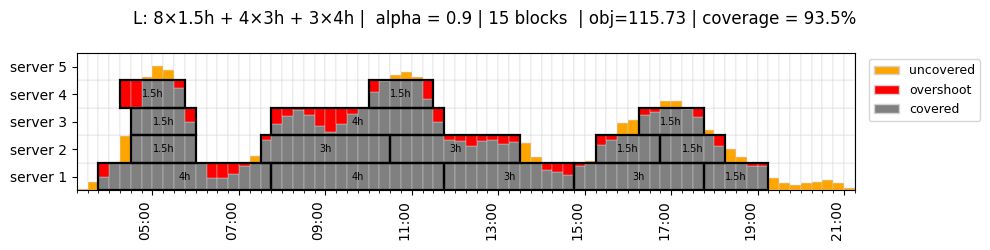

Edited


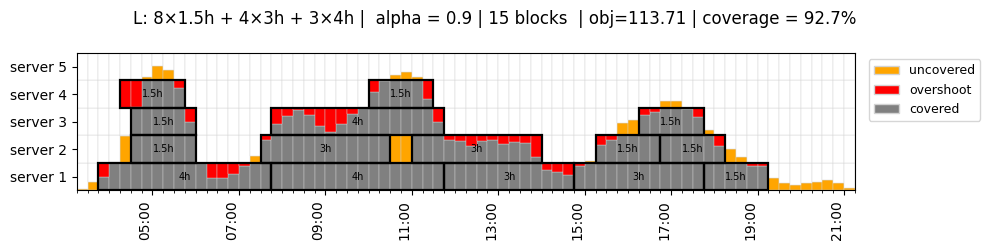

2026-10-19 21:14:50,014 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 50 total tasks, 4 workers


rep 0 (a)  vs  rep edit (b): 1 moved, 0 removed, 0 added
                   a         b   delta
coverage      0.9346    0.9269 -0.0077
objective   115.7299  113.7072 -2.0226
qtime_mean    3.2457    4.4759  1.2302
n_unserved  176.6400  176.6400  0.0000


In [36]:
blocks = {
    '1': [
        (2, 16),   # 0: 03:45-07:45  4h
        (18, 16),   # 1: 07:45-11:45  4h
        (34, 12),   # 2: 11:45-14:45  3h
        (46, 12),   # 3: 14:45-17:45  3h
        (58, 6),   # 4: 17:45-19:15  1.5h
    ],
    '2': [
        (5, 6),   # 0: 04:30-06:00  1.5h
        (17, 12),   # 1: 07:30-10:30  3h
        (31, 12),   # 2: 10:30-13:30  3h
        (48, 6),   # 3: 15:15-16:45  1.5h
        (54, 6),   # 4: 16:45-18:15  1.5h
    ],
    '3': [
        (5, 6),   # 0: 04:30-06:00  1.5h
        (18, 16),   # 1: 07:45-11:45  4h
        (52, 6),   # 2: 16:15-17:45  1.5h
    ],
    '4': [
        (4, 6),   # 0: 04:15-05:45  1.5h
        (27, 6),   # 1: 10:00-11:30  1.5h
    ],
    '5': [],
}

out = run_edit(planner, res, blocks,
               baseline_row=df_pert.loc[df_pert["rep"] == 0].iloc[0])

#### pipeline

2026-10-20 17:43:33,554 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-10-20 17:43:33,569 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[3.0] h, alpha=1.10


running baseline


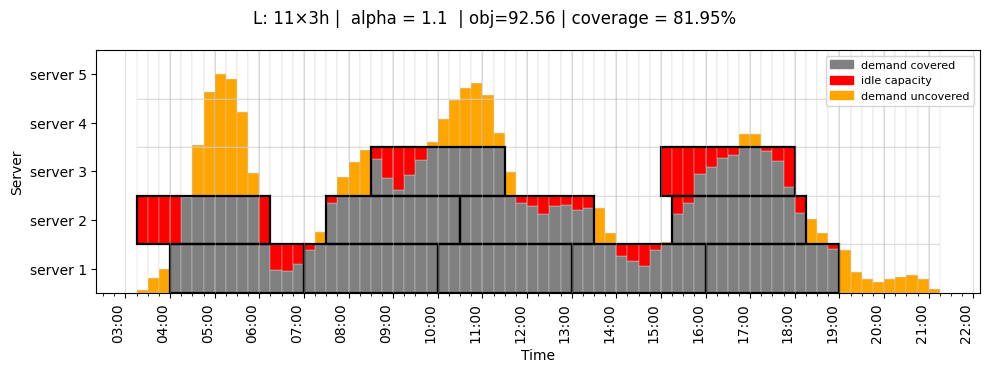

In [91]:
date=dt.datetime(2026, 6, 1)
alpha = 1.1
lengths=[3]
length_totals={3:100}
K_total=100

schedule_or = pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std = preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))
flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

print("running baseline")
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)
res = planner.run_multi(lengths=lengths, length_totals=length_totals, alpha=alpha, K_total=K_total)
plotutils.plot_allocation(res, show_second=False)

In [92]:
# valutazione baseline con simulator
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=100, n_workers=4, timebin=15, base_seed=base_seed)
q_sim_base = float(sim_results.df_kpis.qtime_mean.iloc[0])
n_unserved_base = float(sim_results.df_kpis.n_unserved.iloc[0])
print(f"Avg qtime: {q_sim_base}, Unserved: {n_unserved_base}")

2026-10-20 17:43:47,459 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 100 total tasks, 4 workers


Avg qtime: 60.34388538652024, Unserved: 482.76


In [93]:
import app.services.local_search as ls
import app.services.perturbation as pm

T      = len(planner.arrivals)
labels = res.server_labels
blocks0 = pm.schedule_to_blocks(planner, res)

best, trace = ls.local_search(
    planner.arrivals.to_numpy(), planner.rate_by_label, planner.demand_grid[:len(labels)],
    labels, alpha, blocks0, planner.bin_minutes, step=2,
    unserved_tol=0.0, max_iter=300)
trace

7 moves | q_fluid 58.087 -> 31.226 | unserved 465.98 -> 438.84 | coverage 0.819 -> 0.773


,iter,move,n_neighbors,q_fluid,unserved_fluid,covered_demand,idle_capacity,coverage,objective
0,0,None,0,58.087193,465.98230,113.219200,18.780800,0.819479,92.560320
1,1,"(2, 0, 2)",11,46.672247,365.98230,113.219200,18.780800,0.819479,92.560320
2,2,"(2, 0, 2)",12,41.533935,308.00000,113.216844,18.783156,0.819462,92.555372
3,3,"(3, 1, -2)",10,38.806144,308.00000,112.326393,19.673607,0.813017,90.685425
4,4,"(3, 0, -2)",10,36.078461,308.00000,111.948862,20.051138,0.810284,89.892610
5,5,"(3, 0, -2)",10,33.350816,308.00000,110.338984,21.661016,0.798632,86.511866
6,6,"(2, 3, -2)",10,31.309801,338.83775,108.743070,23.256930,0.787081,83.160447
7,7,"(2, 3, -2)",10,31.225799,438.83775,106.743070,25.256930,0.772605,78.960447


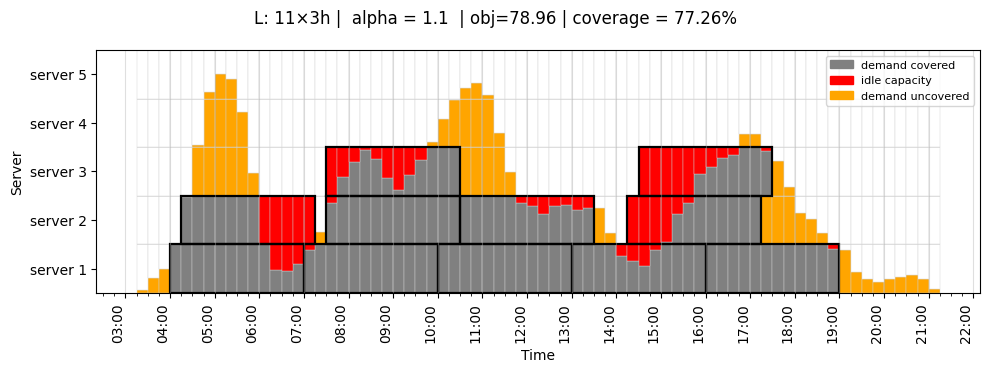

In [94]:
res_ls = pm.res_with_blocks(planner, res, best)
plotutils.plot_allocation(res_ls, show_second=False)

In [95]:
# valutazione baseline con simulator
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res_ls.server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=100, n_workers=4, timebin=15, base_seed=base_seed)
q_sim_end = float(sim_results.df_kpis.qtime_mean.iloc[0])
n_unserved_end = float(sim_results.df_kpis.n_unserved.iloc[0])
print(f"Avg qtime: {q_sim_end}, Unserved: {n_unserved_end}")

2026-10-20 17:44:20,234 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 100 total tasks, 4 workers


Avg qtime: 32.874037051540775, Unserved: 451.09


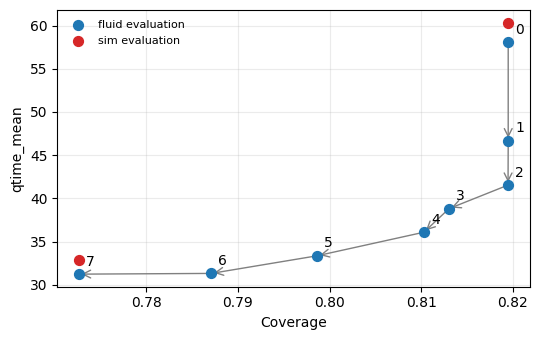

In [97]:
def plot_trace(trace, q_sim_base=None, q_sim_end=None, figsize=(5.5, 3.5)):
    x = trace["coverage"].to_numpy()
    y = trace["q_fluid"].to_numpy()

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(x, y, s=50, zorder=3, label="fluid evaluation")
    for i in range(len(trace) - 1):
        ax.annotate("", xy=(x[i+1], y[i+1]), xytext=(x[i], y[i]),
                    arrowprops=dict(arrowstyle="->", color="gray", lw=1, mutation_scale=14), zorder=2)
    for i, (xi, yi) in enumerate(zip(x, y)):
        ax.annotate(str(trace["iter"].iloc[i]), (xi, yi), xytext=(5, 6), textcoords="offset points")

    if q_sim_base is not None:
        ax.scatter([x[0]], [q_sim_base], s=50, color="tab:red", zorder=4, label="sim evaluation")
    if q_sim_end is not None:
        ax.scatter([x[-1]], [q_sim_end], s=50, color="tab:red", zorder=4)

    ax.set_xlabel("Coverage")
    ax.set_ylabel("qtime_mean")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()

plot_trace(trace, q_sim_base, q_sim_end)